In [1]:

!pip -q install ultralytics opencv-python-headless matplotlib pandas networkx scipy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 3.9 MB/s eta 0:00:00


UPLOAD YOUR SATELLITE IMAGE (JPG, PNG, or TIFF)


Saving Screenshot 2026-10-16 201724.png to Screenshot 2026-10-16 201724.png
Image: Screenshot 2026-10-16 201724.png
Dimensions: 683 x 447


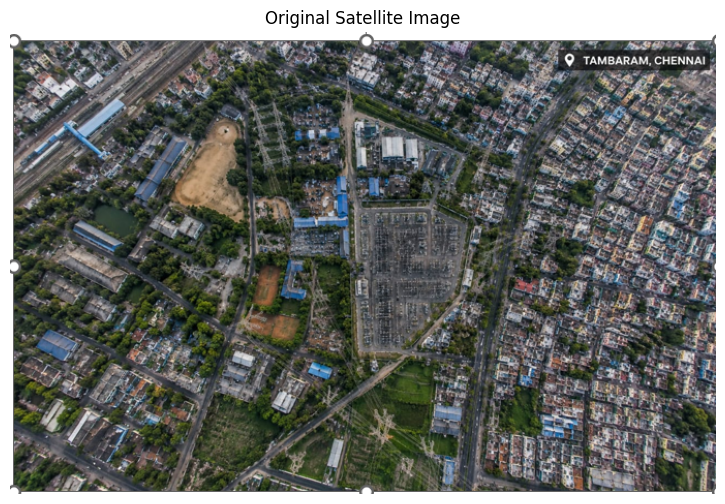

In [2]:

from google.colab import files
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("UPLOAD YOUR SATELLITE IMAGE (JPG, PNG, or TIFF)")
uploaded = files.upload()

image_extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")
image_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(image_extensions)
]

if not image_files:
    raise ValueError(
        "Please upload a satellite image, not a PDF or other file."
    )

image_path = image_files[0]
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not read the uploaded image.")

print("Image:", image_path)
print("Dimensions:", image.shape[1], "x", image.shape[0])

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Satellite Image")
plt.axis("off")
plt.show()


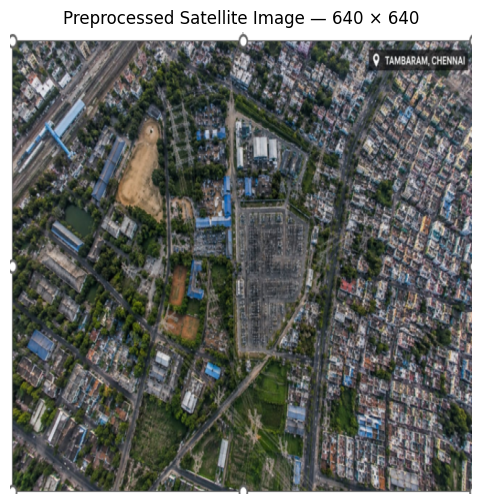

Preprocessed image saved: /content/gridgraph_preprocessed.png


In [3]:

processed = cv2.resize(
    image, (640, 640), interpolation=cv2.INTER_AREA
)

processed_path = "/content/gridgraph_preprocessed.png"
cv2.imwrite(processed_path, processed)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
plt.title("Preprocessed Satellite Image — 640 × 640")
plt.axis("off")
plt.show()

print("Preprocessed image saved:", processed_path)


In [4]:

from ultralytics import YOLO

# Downloads pretrained weights automatically if not already available.
model = YOLO("yolo11n.pt", task="detect")

print("YOLO11 model loaded successfully.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO11 model loaded successfully.



image 1/1 /content/gridgraph_preprocessed.png: 640x640 (no detections), 516.0ms
Speed: 22.0ms preprocess, 516.0ms inference, 14.9ms postprocess per image at shape (1, 3, 640, 640)


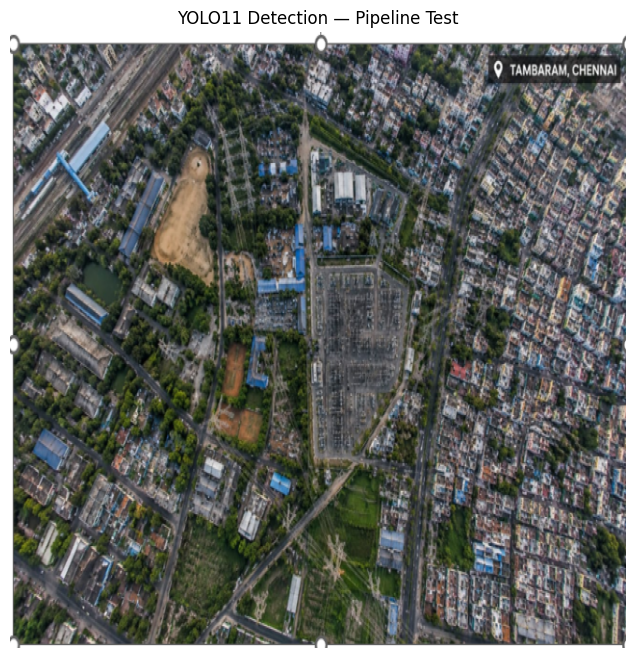

No objects detected at confidence threshold 0.25.
Detection image saved: /content/gridgraph_detection.png


In [5]:

results = model.predict(
    source=processed_path,
    imgsz=640,
    conf=0.25,
    save=False,
    verbose=True
)

result = results[0]

annotated_bgr = result.plot()
annotated_rgb = cv2.cvtColor(
    annotated_bgr, cv2.COLOR_BGR2RGB
)

detection_path = "/content/gridgraph_detection.png"
Image.fromarray(annotated_rgb).save(detection_path)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_rgb)
plt.title("YOLO11 Detection — Pipeline Test")
plt.axis("off")
plt.show()

if result.boxes is not None and len(result.boxes) > 0:
    print("Objects detected:", len(result.boxes))

    for i, box in enumerate(result.boxes):
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        print(
            f"{i + 1}. {result.names[class_id]} "
            f"| Confidence: {confidence:.3f}"
        )
else:
    print("No objects detected at confidence threshold 0.25.")

print("Detection image saved:", detection_path)


In [6]:

import pandas as pd

rows = []

if result.boxes is not None:
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        class_id = int(box.cls.item())

        rows.append({
            "class_name": result.names[class_id],
            "confidence": float(box.conf.item()),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

df = pd.DataFrame(
    rows,
    columns=[
        "class_name", "confidence",
        "x1", "y1", "x2", "y2"
    ]
)

display(df)

csv_path = "/content/gridgraph_detections.csv"
df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)


,class_name,confidence,x1,y1,x2,y2


CSV saved: /content/gridgraph_detections.csv


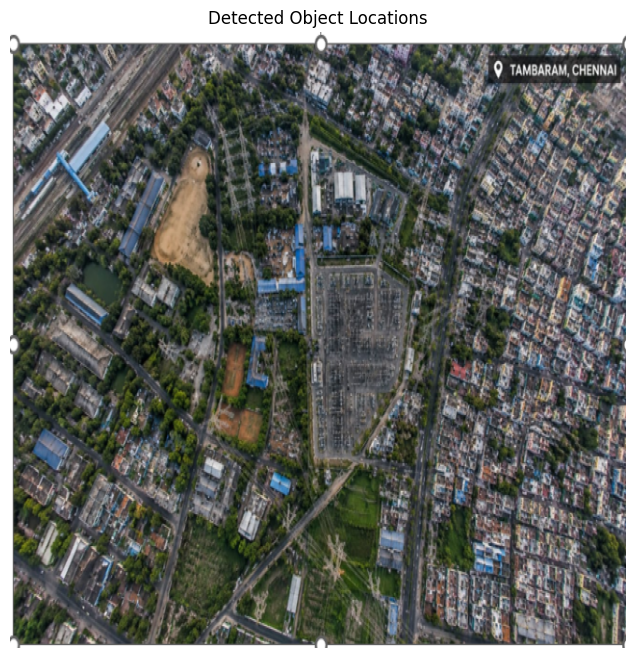

In [7]:

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))

if result.boxes is not None:
    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        class_id = int(box.cls.item())

        plt.scatter(cx, cy, s=70)
        plt.text(
            cx, cy,
            f"{i + 1}: {result.names[class_id]}",
            fontsize=8
        )

plt.title("Detected Object Locations")
plt.axis("off")
plt.show()


In [8]:

import pandas as pd

rows = []

if result.boxes is not None:
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        class_id = int(box.cls.item())

        rows.append({
            "class_name": result.names[class_id],
            "confidence": float(box.conf.item()),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

df = pd.DataFrame(
    rows,
    columns=[
        "class_name", "confidence",
        "x1", "y1", "x2", "y2"
    ]
)

display(df)

csv_path = "/content/gridgraph_detections.csv"
df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)


,class_name,confidence,x1,y1,x2,y2


CSV saved: /content/gridgraph_detections.csv


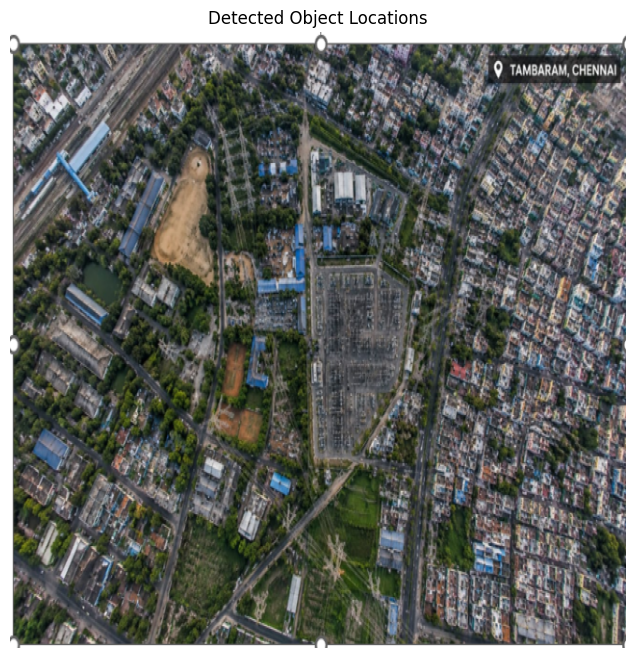

In [9]:

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))

if result.boxes is not None:
    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        class_id = int(box.cls.item())

        plt.scatter(cx, cy, s=70)
        plt.text(
            cx, cy,
            f"{i + 1}: {result.names[class_id]}",
            fontsize=8
        )

plt.title("Detected Object Locations")
plt.axis("off")
plt.show()


In [10]:

from google.colab import files

for path in [
    "/content/gridgraph_preprocessed.png",
    "/content/gridgraph_detection.png",
    "/content/gridgraph_detections.csv"
]:
    if os.path.exists(path):
        files.download(path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

from google.colab import files
import zipfile
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Upload the downloaded Figshare archive
uploaded = files.upload()

zip_files = [f for f in uploaded if f.lower().endswith(".zip")]
if not zip_files:
    raise ValueError("Please upload NZ_Dunedin.zip")

zip_path = zip_files[0]
raw_dir = "/content/gridgraph_raw"
out_dir = "/content/gridgraph_preprocessed"

os.makedirs(raw_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(raw_dir)

print("Dataset extracted successfully.")

# Find image files
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = [
    p for p in Path(raw_dir).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Images found:", len(image_paths))

if not image_paths:
    print("No image files found. Inspect the extracted files:")
    for p in list(Path(raw_dir).rglob("*"))[:30]:
        print(p)


Saving NZ_Dunedin.zip to NZ_Dunedin (1).zip
Dataset extracted successfully.
Images found: 12


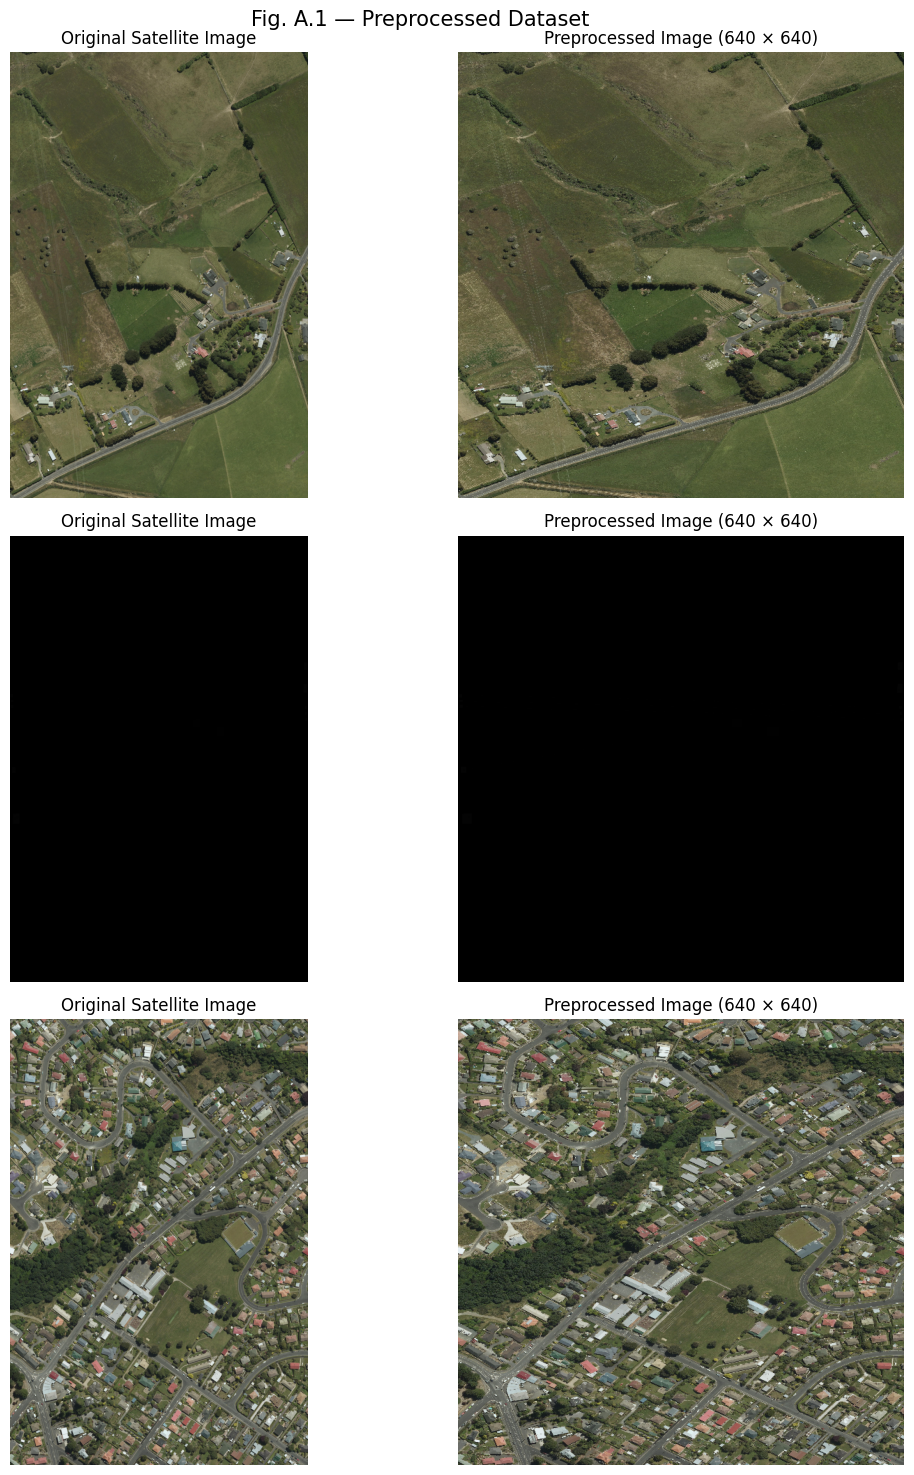

In [12]:

records = []
examples = []

for i, path in enumerate(image_paths, start=1):
    image = cv2.imread(str(path))
    if image is None:
        continue

    h, w = image.shape[:2]
    resized = cv2.resize(image, (640, 640))

    output_name = f"image_{i:05d}.png"
    cv2.imwrite(os.path.join(out_dir, output_name), resized)

    records.append({
        "source_file": str(path),
        "processed_file": output_name,
        "original_width": w,
        "original_height": h,
        "processed_width": 640,
        "processed_height": 640
    })

    if len(examples) < 3:
        examples.append((image.copy(), resized.copy()))

if not records:
    raise ValueError("No readable images were processed.")

pd.DataFrame(records).to_csv(
    "/content/gridgraph_preprocessed_metadata.csv",
    index=False
)

fig, axes = plt.subplots(
    len(examples), 2,
    figsize=(12, 5 * len(examples)),
    squeeze=False
)

for i, (original, processed) in enumerate(examples):
    axes[i, 0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title("Original Satellite Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title("Preprocessed Image (640 × 640)")
    axes[i, 1].axis("off")

plt.suptitle("Fig. A.1 — Preprocessed Dataset", fontsize=15)
plt.tight_layout()
plt.savefig(
    "/content/Fig_A1_Preprocessed_Dataset.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [13]:

import shutil

shutil.make_archive(
    "/content/gridgraph_preprocessed_dataset",
    "zip",
    out_dir
)

files.download("/content/Fig_A1_Preprocessed_Dataset.png")
files.download("/content/gridgraph_preprocessed_dataset.zip")
files.download("/content/gridgraph_preprocessed_metadata.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

!pip -q install ultralytics

from ultralytics import YOLO
from pathlib import Path
import yaml
import os

# Set this to your dataset YAML file.
# Example: /content/gridgraph_dataset/data.yaml
DATA_YAML = "/content/gridgraph_dataset/data.yaml"

if not os.path.isfile(DATA_YAML):
    raise FileNotFoundError(
        f"Dataset YAML not found: {DATA_YAML}\n"
        "Upload and prepare your labeled dataset first."
    )

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

print("Dataset configuration:")
print(yaml.safe_dump(data_config, sort_keys=False))


FileNotFoundError: Dataset YAML not found: /content/gridgraph_dataset/data.yaml
Upload and prepare your labeled dataset first.

In [15]:

model = YOLO("yolo11n.pt")

train_results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    project="/content/gridgraph_runs",
    name="asset_detection",
    seed=42,
    plots=True
)

best_weights = (
    "/content/gridgraph_runs/asset_detection/weights/best.pt"
)

print("\nTraining completed.")
print("Best weights:", best_weights)


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gridgraph_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=asset_detection, nbs=64, nms=None, opset=None, optimi

RuntimeError: Dataset '/content/gridgraph_dataset/data.yaml' error ❌ '/content/gridgraph_dataset/data.yaml' does not exist

In [16]:

!pip -q install ultralytics requests pyyaml pandas matplotlib


In [17]:

import requests
import os
import zipfile
from pathlib import Path

BASE = "/content/gridtracer"
os.makedirs(BASE, exist_ok=True)

url = "https://api.figshare.com/v2/articles/14935434"
response = requests.get(url, timeout=60)
response.raise_for_status()
article = response.json()

print("Dataset:", article["title"])

# Download the Dunedin archive only
files_info = article.get("files", [])
selected = next(
    (f for f in files_info if f["name"] == "NZ_Dunedin.zip"),
    None
)

if selected is None:
    raise RuntimeError(
        "NZ_Dunedin.zip was not found in the Figshare file listing."
    )

zip_path = os.path.join(BASE, selected["name"])

if not os.path.exists(zip_path):
    print("Downloading:", selected["name"])
    with requests.get(
        selected["download_url"], stream=True, timeout=180
    ) as r:
        r.raise_for_status()
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)

RAW = os.path.join(BASE, "raw")
os.makedirs(RAW, exist_ok=True)

with zipfile.ZipFile(zip_path) as z:
    z.extractall(RAW)

print("Extraction complete:", RAW)


Dataset: Electric Transmission Infrastructure Satellite Imagery Dataset for Computer Vision
Downloading: NZ_Dunedin.zip
Extraction complete: /content/gridtracer/raw


In [18]:

from collections import Counter

root = Path(RAW)

all_files = [p for p in root.rglob("*") if p.is_file()]
print("Total files:", len(all_files))

print("\nFile types:")
print(Counter(p.suffix.lower() for p in all_files))

print("\nExample files:")
for p in all_files[:40]:
    print(p.relative_to(root))


Total files: 30

File types:
Counter({'.npz': 6, '.jpg': 6, '.csv': 6, '.geojson': 6, '.png': 6})

Example files:
NZ_Dunedin/NZ_Dunedin_5.npz
NZ_Dunedin/NZ_Dunedin_5.jpg
NZ_Dunedin/NZ_Dunedin_6.csv
NZ_Dunedin/NZ_Dunedin_3.npz
NZ_Dunedin/NZ_Dunedin_6.geojson
NZ_Dunedin/NZ_Dunedin_4.geojson
NZ_Dunedin/NZ_Dunedin_2.csv
NZ_Dunedin/NZ_Dunedin_1.geojson
NZ_Dunedin/NZ_Dunedin_2.geojson
NZ_Dunedin/NZ_Dunedin_5.geojson
NZ_Dunedin/NZ_Dunedin_5.csv
NZ_Dunedin/NZ_Dunedin_2_multiclass.png
NZ_Dunedin/NZ_Dunedin_4.jpg
NZ_Dunedin/NZ_Dunedin_4.npz
NZ_Dunedin/NZ_Dunedin_3.geojson
NZ_Dunedin/NZ_Dunedin_2.npz
NZ_Dunedin/NZ_Dunedin_1.npz
NZ_Dunedin/NZ_Dunedin_1.jpg
NZ_Dunedin/NZ_Dunedin_5_multiclass.png
NZ_Dunedin/NZ_Dunedin_6.jpg
NZ_Dunedin/NZ_Dunedin_1_multiclass.png
NZ_Dunedin/NZ_Dunedin_2.jpg
NZ_Dunedin/NZ_Dunedin_1.csv
NZ_Dunedin/NZ_Dunedin_6.npz
NZ_Dunedin/NZ_Dunedin_4_multiclass.png
NZ_Dunedin/NZ_Dunedin_4.csv
NZ_Dunedin/NZ_Dunedin_3.jpg
NZ_Dunedin/NZ_Dunedin_3.csv
NZ_Dunedin/NZ_Dunedin_3_multiclass

In [19]:

image_extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

label_files = [
    p for p in root.rglob("*.txt")
    if p.is_file()
]

yaml_files = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in {".yaml", ".yml"}
]

print("Images found:", len(images))
print("Text label files:", len(label_files))
print("YAML files:", len(yaml_files))

for p in yaml_files:
    print("YAML:", p)

if not yaml_files:
    print(
        "\nNo dataset YAML found. The dataset must be converted "
        "from its documented annotation format before YOLO training."
    )


Images found: 12
Text label files: 0
YAML files: 0

No dataset YAML found. The dataset must be converted from its documented annotation format before YOLO training.


In [21]:

from pathlib import Path
import os

ROOT = Path("/content/gridtracer/raw")

if not ROOT.exists():
    ROOT = Path("/content/gridtracer")

print("=== DATASET FILE INSPECTION ===")

for path in ROOT.rglob("*"):
    if path.is_file():
        print(
            f"{path.relative_to(ROOT)} "
            f"| {path.suffix or '[no extension]'} "
            f"| {path.stat().st_size / 1024:.1f} KB"
        )


=== DATASET FILE INSPECTION ===
NZ_Dunedin/NZ_Dunedin_5.npz | .npz | 37.7 KB
NZ_Dunedin/NZ_Dunedin_5.jpg | .jpg | 2051.6 KB
NZ_Dunedin/NZ_Dunedin_6.csv | .csv | 6.1 KB
NZ_Dunedin/NZ_Dunedin_3.npz | .npz | 74.0 KB
NZ_Dunedin/NZ_Dunedin_6.geojson | .geojson | 34.3 KB
NZ_Dunedin/NZ_Dunedin_4.geojson | .geojson | 350.0 KB
NZ_Dunedin/NZ_Dunedin_2.csv | .csv | 14.4 KB
NZ_Dunedin/NZ_Dunedin_1.geojson | .geojson | 120.0 KB
NZ_Dunedin/NZ_Dunedin_2.geojson | .geojson | 77.3 KB
NZ_Dunedin/NZ_Dunedin_5.geojson | .geojson | 37.5 KB
NZ_Dunedin/NZ_Dunedin_5.csv | .csv | 6.6 KB
NZ_Dunedin/NZ_Dunedin_2_multiclass.png | .png | 25.7 KB
NZ_Dunedin/NZ_Dunedin_4.jpg | .jpg | 2492.5 KB
NZ_Dunedin/NZ_Dunedin_4.npz | .npz | 68.8 KB
NZ_Dunedin/NZ_Dunedin_3.geojson | .geojson | 221.2 KB
NZ_Dunedin/NZ_Dunedin_2.npz | .npz | 26.5 KB
NZ_Dunedin/NZ_Dunedin_1.npz | .npz | 56.7 KB
NZ_Dunedin/NZ_Dunedin_1.jpg | .jpg | 2249.8 KB
NZ_Dunedin/NZ_Dunedin_5_multiclass.png | .png | 33.2 KB
NZ_Dunedin/NZ_Dunedin_6.jpg | .jpg |

In [22]:

from collections import Counter

annotation_extensions = {
    ".json", ".xml", ".csv", ".geojson",
    ".shp", ".dbf", ".prj", ".gpkg",
    ".mat", ".npy", ".npz", ".txt"
}

files_found = [
    p for p in ROOT.rglob("*") if p.is_file()
]

print("=== ANNOTATION FILE SUMMARY ===")

counts = Counter(p.suffix.lower() for p in files_found)

for ext, count in sorted(counts.items()):
    print(f"{ext or '[no extension]'}: {count}")

annotations = [
    p for p in files_found
    if p.suffix.lower() in annotation_extensions
]

print("\nPotential annotation files:")
for p in annotations:
    print(p)


=== ANNOTATION FILE SUMMARY ===
.csv: 6
.geojson: 6
.jpg: 6
.npz: 6
.png: 6

Potential annotation files:
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_5.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_6.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_6.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_4.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_5.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_5.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_4.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_6.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_D

In [23]:

from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

if not ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {ROOT}")

# 1. Inspect CSV files
print("=" * 60)
print("1. CSV ANNOTATIONS")
print("=" * 60)

for path in sorted(ROOT.glob("*.csv")):
    print(f"\nFILE: {path.name}")
    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print("Could not read CSV:", e)

# 2. Inspect GeoJSON files
print("\n" + "=" * 60)
print("2. GEOJSON ANNOTATIONS")
print("=" * 60)

for path in sorted(ROOT.glob("*.geojson")):
    print(f"\nFILE: {path.name}")
    try:
        with open(path, "r") as f:
            data = json.load(f)

        features = data.get("features", [])
        print("Feature count:", len(features))
        print("GeoJSON type:", data.get("type"))

        for feature in features[:3]:
            print("Properties:", feature.get("properties", {}))
            geometry = feature.get("geometry") or {}
            print("Geometry type:", geometry.get("type"))
            print("Coordinates sample:",
                  str(geometry.get("coordinates", []))[:250])
    except Exception as e:
        print("Could not read GeoJSON:", e)

# 3. Inspect NPZ arrays
print("\n" + "=" * 60)
print("3. NPZ ARRAYS")
print("=" * 60)

for path in sorted(ROOT.glob("*.npz")):
    print(f"\nFILE: {path.name}")
    try:
        with np.load(path, allow_pickle=False) as archive:
            for key in archive.files:
                arr = archive[key]
                print(
                    f"Key: {key} | Shape: {arr.shape} | "
                    f"Data type: {arr.dtype}"
                )
                if arr.size and arr.size < 30:
                    print("Values:", arr)
    except Exception as e:
        print("Could not read NPZ:", e)


1. CSV ANNOTATIONS

FILE: NZ_Dunedin_1.csv
Shape: (326, 9)
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
 Unnamed: 0.1  Unnamed: 0 Label  Object    Type          X         Y  height  width
            0           0    EN       1 Polygon 961.808231  2.341115  4800.0 3200.0
            1           1    EN       1 Polygon 961.418045 22.240596  4800.0 3200.0
            2           2    EN       1 Polygon 985.609570 22.240596  4800.0 3200.0

FILE: NZ_Dunedin_2.csv
Shape: (209, 9)
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
 Unnamed: 0.1  Unnamed: 0 Label  Object    Type          X           Y  height  width
            0           0     T       1 Polygon 167.280086 1773.030662  4800.0 3200.0
            1           1     T       1 Polygon 167.280086 1793.767863  4800.0 3200.0
            2           2     T       1 Polygon 186.634807 1795.150343  4800.0 3200.0

FILE: NZ_Dunedin_3.csv
Shape

In [24]:

!pip -q install ultralytics pyyaml

from ultralytics import YOLO
from pathlib import Path
import yaml
import os

# --------------------------------------------------
# 1. Locate the dataset configuration
# --------------------------------------------------
SEARCH_DIRS = [
    Path("/content/gridtracer"),
    Path("/content/gridgraph_dataset"),
    Path("/content")
]

yaml_candidates = []

for folder in SEARCH_DIRS:
    if folder.exists():
        yaml_candidates.extend(
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {".yaml", ".yml"}
            and "site-packages" not in str(p)
        )

# Prefer a file named data.yaml
yaml_candidates = sorted(
    set(yaml_candidates),
    key=lambda p: (p.name.lower() != "data.yaml", len(str(p)))
)

if not yaml_candidates:
    raise FileNotFoundError(
        "No dataset YAML was found. The dataset must be prepared "
        "in YOLO format before training. Inspect the extracted "
        "GridTracer files and convert their annotations first."
    )

DATA_YAML = str(yaml_candidates[0])
print("Using dataset configuration:", DATA_YAML)

# --------------------------------------------------
# 2. Read and validate the YAML
# --------------------------------------------------
with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

if not isinstance(config, dict):
    raise ValueError("The dataset YAML must contain a mapping.")

missing = [key for key in ("train", "val", "names") if key not in config]
if missing:
    raise ValueError(f"Dataset YAML is missing required fields: {missing}")

if not isinstance(config["names"], (dict, list)):
    raise ValueError("'names' must be a list or dictionary of class names.")

print("\nDataset classes:", config["names"])

# Resolve relative paths using the YAML's path setting or its directory.
yaml_dir = Path(DATA_YAML).parent
dataset_root = Path(config.get("path", yaml_dir))

if not dataset_root.is_absolute():
    dataset_root = (yaml_dir / dataset_root).resolve()

def resolve_dataset_path(value):
    p = Path(value)
    if p.is_absolute():
        return p
    return (dataset_root / p).resolve()

for split in ("train", "val"):
    value = config[split]
    entries = value if isinstance(value, list) else [value]

    for entry in entries:
        p = resolve_dataset_path(entry)
        if not p.exists():
            raise FileNotFoundError(
                f"Dataset {split} path does not exist: {p}"
            )
        print(f"{split} path verified:", p)

# --------------------------------------------------
# 3. Train YOLO11
# --------------------------------------------------
model = YOLO("yolo11n.pt")

model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    project="/content/gridgraph_runs",
    name="asset_detection",
    seed=42,
    plots=True
)

# --------------------------------------------------
# 4. Load the best checkpoint
# --------------------------------------------------
best_weights = Path(
    "/content/gridgraph_runs/asset_detection/weights/best.pt"
)

if not best_weights.is_file():
    raise FileNotFoundError(
        f"Training finished without the expected checkpoint: {best_weights}"
    )

trained_model = YOLO(str(best_weights))

# --------------------------------------------------
# 5. Evaluate on test split if it exists
# --------------------------------------------------
if "test" in config:
    test_value = config["test"]
    test_entries = (
        test_value if isinstance(test_value, list) else [test_value]
    )

    for entry in test_entries:
        test_path = resolve_dataset_path(entry)
        if not test_path.exists():
            raise FileNotFoundError(
                f"Test path in YAML does not exist: {test_path}"
            )

    metrics = trained_model.val(
        data=DATA_YAML,
        split="test",
        imgsz=640
    )
else:
    print(
        "No test split defined in YAML; evaluating on validation split instead."
    )
    metrics = trained_model.val(
        data=DATA_YAML,
        split="val",
        imgsz=640
    )

# --------------------------------------------------
# 6. Print actual evaluation metrics
# --------------------------------------------------
print("\n=== GRIDGRAPH ASSET DETECTION RESULTS ===")
print(f"Precision:     {metrics.box.mp:.4f}")
print(f"Recall:        {metrics.box.mr:.4f}")
print(f"mAP@0.50:      {metrics.box.map50:.4f}")
print(f"mAP@0.50:0.95: {metrics.box.map:.4f}")

print("\nBest weights saved at:", best_weights)
print("Evaluation plots are saved in the YOLO run directory.")


Using dataset configuration: /content/.config/.last_opt_in_prompt.yaml


ValueError: Dataset YAML is missing required fields: ['train', 'val', 'names']

In [25]:

import os
from pathlib import Path

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

print("Dataset folder exists:", ROOT.exists())

if ROOT.exists():
    for path in sorted(ROOT.rglob("*")):
        if path.is_file():
            print(path.name, "—", path.stat().st_size, "bytes")

print("\nSearching for dataset YAML files:")
for path in Path("/content/gridtracer").rglob("*.yaml"):
    print(path)



Dataset folder exists: True
NZ_Dunedin_1.csv — 23166 bytes
NZ_Dunedin_1.geojson — 122833 bytes
NZ_Dunedin_1.jpg — 2303774 bytes
NZ_Dunedin_1.npz — 58079 bytes
NZ_Dunedin_1_multiclass.png — 44565 bytes
NZ_Dunedin_2.csv — 14794 bytes
NZ_Dunedin_2.geojson — 79171 bytes
NZ_Dunedin_2.jpg — 2373016 bytes
NZ_Dunedin_2.npz — 27137 bytes
NZ_Dunedin_2_multiclass.png — 26322 bytes
NZ_Dunedin_3.csv — 41703 bytes
NZ_Dunedin_3.geojson — 226513 bytes
NZ_Dunedin_3.jpg — 2422995 bytes
NZ_Dunedin_3.npz — 75808 bytes
NZ_Dunedin_3_multiclass.png — 61124 bytes
NZ_Dunedin_4.csv — 62417 bytes
NZ_Dunedin_4.geojson — 358413 bytes
NZ_Dunedin_4.jpg — 2552352 bytes
NZ_Dunedin_4.npz — 70428 bytes
NZ_Dunedin_4_multiclass.png — 56173 bytes
NZ_Dunedin_5.csv — 6780 bytes
NZ_Dunedin_5.geojson — 38368 bytes
NZ_Dunedin_5.jpg — 2100850 bytes
NZ_Dunedin_5.npz — 38600 bytes
NZ_Dunedin_5_multiclass.png — 34019 bytes
NZ_Dunedin_6.csv — 6254 bytes
NZ_Dunedin_6.geojson — 35143 bytes
NZ_Dunedin_6.jpg — 2052466 bytes
NZ_Dunedin_6

In [26]:

import json
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

csv_files = list(ROOT.glob("*.csv"))
geojson_files = list(ROOT.glob("*.geojson"))
npz_files = list(ROOT.glob("*.npz"))

if csv_files:
    print("CSV sample:")
    df = pd.read_csv(csv_files[0])
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string())

if geojson_files:
    print("\nGeoJSON sample:")
    with open(geojson_files[0], "r") as f:
        data = json.load(f)
    print("Top-level keys:", list(data.keys()))
    print(json.dumps(data, indent=2)[:4000])

if npz_files:
    print("\nNPZ sample:")
    data = np.load(npz_files[0], allow_pickle=True)
    for key in data.files:
        arr = data[key]
        print(key, "shape:", getattr(arr, "shape", None),
              "dtype:", getattr(arr, "dtype", None))
        if getattr(arr, "size", 0) > 0:
            print("Sample:", repr(arr.flat[0])[:300])


CSV sample:
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
   Unnamed: 0.1  Unnamed: 0 Label  Object     Type            X            Y  height   width
0             0           0    EN       1  Polygon  3132.410067  1980.087933  4800.0  3200.0
1             1           1    EN       1  Polygon  3132.410067  2058.619638  4800.0  3200.0
2             2           2    EN       1  Polygon  3197.606199  2063.064829  4800.0  3200.0
3             3           3    EN       1  Polygon  3194.642739  1975.642742  4800.0  3200.0
4             4           4     T       2  Polygon  2901.227900  2001.817617  4800.0  3200.0

GeoJSON sample:
Top-level keys: ['type', 'crs', 'features']
{
  "type": "FeatureCollection",
  "crs": {
    "type": "name",
    "properties": {
      "name": "urn:ogc:def:crs:OGC:1.3:CRS84"
    }
  },
  "features": [
    {
      "type": "Feature",
      "properties": {
        "label": "EN",
        "filename": "NZ_Dunedin_6.geojso

In [27]:

from pathlib import Path

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

if not ROOT.exists():
    print("Dataset folder not found:", ROOT)
else:
    for p in sorted(ROOT.rglob("*")):
        if p.is_file():
            print(p)


/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.jpg
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_1_multiclass.png
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.jpg
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_2_multiclass.png
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.jpg
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3.npz
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_3_multiclass.png
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_4.csv
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_4.geojson
/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin_4.jpg
/content/gridtr

In [28]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

for file in sorted(ROOT.glob("*.csv"))[:1]:
    print("\n===== CSV =====")
    df = pd.read_csv(file)
    print("File:", file.name)
    print("Columns:", df.columns.tolist())
    print(df.head().to_string())

for file in sorted(ROOT.glob("*.geojson"))[:1]:
    print("\n===== GEOJSON =====")
    with open(file, "r") as f:
        geo = json.load(f)
    print(json.dumps(geo, indent=2)[:5000])

for file in sorted(ROOT.glob("*.npz"))[:1]:
    print("\n===== NPZ =====")
    data = np.load(file, allow_pickle=True)
    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")
        print("Sample:", repr(arr.flat[0])[:300] if arr.size else "Empty")



===== CSV =====
File: NZ_Dunedin_1.csv
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
   Unnamed: 0.1  Unnamed: 0 Label  Object     Type            X           Y  height   width
0             0           0    EN       1  Polygon   961.808231    2.341115  4800.0  3200.0
1             1           1    EN       1  Polygon   961.418045   22.240596  4800.0  3200.0
2             2           2    EN       1  Polygon   985.609570   22.240596  4800.0  3200.0
3             3           3    EN       1  Polygon   985.219384    2.731301  4800.0  3200.0
4             4           4     T       2  Polygon  1021.502995  403.217853  4800.0  3200.0

===== GEOJSON =====
{
  "type": "FeatureCollection",
  "crs": {
    "type": "name",
    "properties": {
      "name": "urn:ogc:def:crs:OGC:1.3:CRS84"
    }
  },
  "features": [
    {
      "type": "Feature",
      "properties": {
        "label": "EN",
        "filename": "NZ_Dunedin_1.geojson",
        "count

In [29]:

from PIL import Image

for file in sorted(ROOT.rglob("*")):
    if file.suffix.lower() in (".jpg", ".jpeg", ".png"):
        try:
            with Image.open(file) as img:
                print(file.name, "size:", img.size, "mode:", img.mode)
        except Exception as e:
            print(file.name, "ERROR:", e)


NZ_Dunedin_1.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_1_multiclass.png size: (3200, 4800) mode: L
NZ_Dunedin_2.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_2_multiclass.png size: (3200, 4800) mode: L
NZ_Dunedin_3.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_3_multiclass.png size: (3200, 4800) mode: L
NZ_Dunedin_4.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_4_multiclass.png size: (3200, 4800) mode: L
NZ_Dunedin_5.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_5_multiclass.png size: (3200, 4800) mode: L
NZ_Dunedin_6.jpg size: (3200, 4800) mode: RGB
NZ_Dunedin_6_multiclass.png size: (3200, 4800) mode: L


In [30]:

!pip install -q ultralytics scikit-learn pandas matplotlib seaborn


In [31]:

from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = "/content/runs/detect/train/weights/best.pt"
DATA_YAML = "/content/gridtracer/data.yaml"

assert Path(MODEL_PATH).is_file(), (
    f"Trained model not found: {MODEL_PATH}. Train YOLO first."
)
assert Path(DATA_YAML).is_file(), (
    f"Dataset YAML not found: {DATA_YAML}. Create valid YOLO labels and YAML first."
)

model = YOLO(MODEL_PATH)
print("Model loaded successfully.")


AssertionError: Trained model not found: /content/runs/detect/train/weights/best.pt. Train YOLO first.

In [33]:

from pathlib import Path

paths = {
    "Trained YOLO model": "/content/runs/detect/train/weights/best.pt",
    "Dataset YAML": "/content/gridtracer/data.yaml",
    "Extracted dataset": "/content/gridtracer/raw/NZ_Dunedin",
}

for name, path in paths.items():
    p = Path(path)
    print(f"{name}: {'FOUND' if p.exists() else 'NOT FOUND'}")
    if p.is_dir():
        print("  Files:", len([x for x in p.rglob("*") if x.is_file()]))


Trained YOLO model: NOT FOUND
Dataset YAML: NOT FOUND
Extracted dataset: FOUND
  Files: 30


In [34]:

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

for p in sorted(ROOT.glob("*.csv"))[:2]:
    print("\nCSV:", p.name)
    df = pd.read_csv(p)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))

for p in sorted(ROOT.glob("*.geojson"))[:1]:
    print("\nGeoJSON:", p.name)
    with open(p) as f:
        data = json.load(f)
    print(json.dumps(data, indent=2)[:3000])



CSV: NZ_Dunedin_1.csv
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
 Unnamed: 0.1  Unnamed: 0 Label  Object    Type          X         Y  height  width
            0           0    EN       1 Polygon 961.808231  2.341115  4800.0 3200.0
            1           1    EN       1 Polygon 961.418045 22.240596  4800.0 3200.0
            2           2    EN       1 Polygon 985.609570 22.240596  4800.0 3200.0

CSV: NZ_Dunedin_2.csv
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'Label', 'Object', 'Type', 'X', 'Y', 'height', 'width']
 Unnamed: 0.1  Unnamed: 0 Label  Object    Type          X           Y  height  width
            0           0     T       1 Polygon 167.280086 1773.030662  4800.0 3200.0
            1           1     T       1 Polygon 167.280086 1793.767863  4800.0 3200.0
            2           2     T       1 Polygon 186.634807 1795.150343  4800.0 3200.0

GeoJSON: NZ_Dunedin_1.geojson
{
  "type": "FeatureCollection",
  "crs": {
    "ty

In [35]:

from pathlib import Path
from PIL import Image
import pandas as pd
import json

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

if not ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {ROOT}")

print("=== IMAGE DIMENSIONS ===")
for p in sorted(ROOT.iterdir()):
    if p.suffix.lower() in (".jpg", ".jpeg", ".png"):
        try:
            with Image.open(p) as img:
                print(f"{p.name}: {img.width} x {img.height}")
        except Exception as e:
            print("Image error:", p.name, e)

print("\n=== CSV ANNOTATION SUMMARY ===")
for p in sorted(ROOT.glob("*.csv")):
    df = pd.read_csv(p)
    print(f"\n{p.name}: {len(df)} rows")
    print("Labels:", df["Label"].value_counts().to_dict())
    print("Unique objects:", df["Object"].nunique())
    print("Coordinate ranges:")
    print(df[["X", "Y"]].agg(["min", "max"]))

print("\n=== GEOJSON SUMMARY ===")
for p in sorted(ROOT.glob("*.geojson"))[:2]:
    with open(p, "r") as f:
        data = json.load(f)
    print(f"\n{p.name}: {len(data.get('features', []))} features")
    for feature in data.get("features", [])[:3]:
        props = feature.get("properties", {})
        print("Label:", props.get("label"))
        print("Pixel coordinates:", props.get("pixel_coordinates"))


=== IMAGE DIMENSIONS ===
NZ_Dunedin_1.jpg: 3200 x 4800
NZ_Dunedin_1_multiclass.png: 3200 x 4800
NZ_Dunedin_2.jpg: 3200 x 4800
NZ_Dunedin_2_multiclass.png: 3200 x 4800
NZ_Dunedin_3.jpg: 3200 x 4800
NZ_Dunedin_3_multiclass.png: 3200 x 4800
NZ_Dunedin_4.jpg: 3200 x 4800
NZ_Dunedin_4_multiclass.png: 3200 x 4800
NZ_Dunedin_5.jpg: 3200 x 4800
NZ_Dunedin_5_multiclass.png: 3200 x 4800
NZ_Dunedin_6.jpg: 3200 x 4800
NZ_Dunedin_6_multiclass.png: 3200 x 4800

=== CSV ANNOTATION SUMMARY ===

NZ_Dunedin_1.csv: 326 rows
Labels: {'T': 176, 'L': 64, 'EN': 56, 'OT': 20, 'SS': 10}
Unique objects: 73
Coordinate ranges:
               X            Y
min     6.438067     2.341115
max  3200.315159  4800.013264

NZ_Dunedin_2.csv: 209 rows
Labels: {'T': 128, 'L': 41, 'EN': 40}
Unique objects: 47
Coordinate ranges:
               X            Y
min     5.141455  1359.562991
max  3192.291005  3100.083042

NZ_Dunedin_3.csv: 583 rows
Labels: {'T': 352, 'L': 123, 'EN': 52, 'OT': 40, 'SS': 16}
Unique objects: 136
Co

In [36]:

from pathlib import Path
import json
import random
import shutil
import yaml
from PIL import Image

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")
OUT = Path("/content/gridgraph_yolo")

# Classes found in the dataset annotations
CLASSES = ["EN", "L", "OT", "SS", "T"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

# Reset output directory for a clean run
if OUT.exists():
    shutil.rmtree(OUT)

for split in ["train", "val"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

geojson_files = sorted(ROOT.glob("NZ_Dunedin_*.geojson"))
if len(geojson_files) < 2:
    raise RuntimeError("Expected GeoJSON annotation files were not found.")

# Split by image/tile to avoid putting the same tile in both sets
random.seed(42)
random.shuffle(geojson_files)
val_count = max(1, round(len(geojson_files) * 0.2))
val_files = geojson_files[:val_count]
train_files = geojson_files[val_count:]

def convert_tile(geojson_path, split):
    tile_name = geojson_path.stem
    image_path = ROOT / f"{tile_name}.jpg"

    if not image_path.exists():
        raise FileNotFoundError(f"Missing original image: {image_path}")

    with Image.open(image_path) as img:
        image_w, image_h = img.size

    with open(geojson_path, "r") as f:
        geo = json.load(f)

    yolo_lines = []
    skipped = 0

    for feature in geo.get("features", []):
        props = feature.get("properties", {})
        label = str(props.get("label", "")).strip()

        if label not in CLASS_TO_ID:
            skipped += 1
            continue

        # Dataset provides polygon vertices in pixel_coordinates.
        points = props.get("pixel_coordinates")

        # Fallback: GeoJSON polygon coordinates are geographic, not pixels.
        if not points:
            skipped += 1
            continue

        try:
            xs = [float(p[0]) for p in points]
            ys = [float(p[1]) for p in points]
        except (TypeError, ValueError, IndexError):
            skipped += 1
            continue

        # Clip the polygon bounds to the image.
        x1 = max(0.0, min(image_w, min(xs)))
        y1 = max(0.0, min(image_h, min(ys)))
        x2 = max(0.0, min(image_w, max(xs)))
        y2 = max(0.0, min(image_h, max(ys)))

        if x2 <= x1 or y2 <= y1:
            skipped += 1
            continue

        # YOLO format: class_id, normalized center_x, center_y, width, height
        xc = ((x1 + x2) / 2) / image_w
        yc = ((y1 + y2) / 2) / image_h
        bw = (x2 - x1) / image_w
        bh = (y2 - y1) / image_h

        yolo_lines.append(
            f"{CLASS_TO_ID[label]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
        )

    shutil.copy2(image_path, OUT / "images" / split / image_path.name)

    label_path = OUT / "labels" / split / f"{tile_name}.txt"
    label_path.write_text("\n".join(yolo_lines) + ("\n" if yolo_lines else ""))

    print(
        f"{split:5} | {tile_name} | "
        f"{len(yolo_lines)} boxes | skipped: {skipped} | "
        f"image: {image_w}x{image_h}"
    )

for p in train_files:
    convert_tile(p, "train")

for p in val_files:
    convert_tile(p, "val")

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(CLASSES)}
}

yaml_path = OUT / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nCreated dataset:", OUT)
print("Dataset configuration:", yaml_path)
print(yaml_path.read_text())


train | NZ_Dunedin_2 | 47 boxes | skipped: 0 | image: 3200x4800
train | NZ_Dunedin_3 | 136 boxes | skipped: 0 | image: 3200x4800
train | NZ_Dunedin_5 | 23 boxes | skipped: 0 | image: 3200x4800
train | NZ_Dunedin_1 | 73 boxes | skipped: 0 | image: 3200x4800
train | NZ_Dunedin_6 | 21 boxes | skipped: 0 | image: 3200x4800
val   | NZ_Dunedin_4 | 219 boxes | skipped: 0 | image: 3200x4800

Created dataset: /content/gridgraph_yolo
Dataset configuration: /content/gridgraph_yolo/data.yaml
path: /content/gridgraph_yolo
train: images/train
val: images/val
names:
  0: EN
  1: L
  2: OT
  3: SS
  4: T



In [37]:

from pathlib import Path

OUT = Path("/content/gridgraph_yolo")

for split in ["train", "val"]:
    images = list((OUT / "images" / split).glob("*.jpg"))
    labels = list((OUT / "labels" / split).glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} label files")

    for label_file in labels:
        for line in label_file.read_text().splitlines():
            values = line.split()
            assert len(values) == 5, f"Bad label: {label_file}"
            cls, x, y, w, h = map(float, values)
            assert cls.is_integer() and 0 <= cls < 5
            assert all(0 <= v <= 1 for v in (x, y, w, h))
            assert w > 0 and h > 0

print("Label format checks passed.")


train: 5 images, 5 label files
val: 1 images, 1 label files
Label format checks passed.


In [38]:

!pip install -q ultralytics


In [39]:

from ultralytics import YOLO
from pathlib import Path

DATA_YAML = "/content/gridgraph_yolo/data.yaml"

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=2,
    device=0,
    project="/content/runs/gridgraph",
    name="power_distribution",
    patience=10,
    plots=True,
    seed=42
)

best_model_path = (
    "/content/runs/gridgraph/power_distribution/weights/best.pt"
)
print("Best model:", best_model_path)
print("Model exists:", Path(best_model_path).exists())


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu 


ValueError: Invalid CUDA 'device=0' requested. Use 'device=cpu' or pass valid CUDA device(s) if available, i.e. 'device=0' or 'device=0,1,2,3' for Multi-GPU.

torch.cuda.is_available(): False
torch.cuda.device_count(): 0
os.environ['CUDA_VISIBLE_DEVICES']: None
See https://pytorch.org/get-started/locally/ for up-to-date torch install instructions if no CUDA devices are seen by torch.


In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled in this runtime.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:

from ultralytics import YOLO
from pathlib import Path
import torch

DATA_YAML = "/content/gridgraph_yolo/data.yaml"

if not Path(DATA_YAML).is_file():
    raise FileNotFoundError(f"Dataset configuration missing: {DATA_YAML}")

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=1,
    device="cpu",
    workers=2,
    project="/content/runs/gridgraph",
    name="power_distribution",
    patience=10,
    plots=True,
    seed=42
)

best_model_path = (
    "/content/runs/gridgraph/power_distribution/weights/best.pt"
)

print("Best model exists:", Path(best_model_path).exists())
print("Best model path:", best_model_path)


ModuleNotFoundError: No module named 'ultralytics'

In [3]:

import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


ModuleNotFoundError: No module named 'ultralytics'

In [4]:

%pip install -q ultralytics pyyaml pandas numpy pillow matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.1 MB/s eta 0:00:00


In [5]:

from pathlib import Path
import torch

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    print("Using CPU; training may be slower.")
    DEVICE = "cpu"

if not ROOT.exists():
    raise FileNotFoundError(
        f"Dataset not found at {ROOT}. "
        "If the Colab runtime restarted, re-upload and extract NZ_Dunedin.zip."
    )

print("Images:", len(list(ROOT.glob("*.jpg"))))
print("GeoJSON annotations:", len(list(ROOT.glob("*.geojson"))))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


FileNotFoundError: Dataset not found at /content/gridtracer/raw/NZ_Dunedin. If the Colab runtime restarted, re-upload and extract NZ_Dunedin.zip.

In [6]:

from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))


Saving NZ_Dunedin.zip to NZ_Dunedin.zip
Uploaded files: ['NZ_Dunedin.zip']


In [7]:

from pathlib import Path
import zipfile

zip_files = [
    Path("/content") / name
    for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "Please upload NZ_Dunedin.zip using Cell 1."
    )

extract_root = Path("/content/gridtracer/raw/NZ_Dunedin")
extract_root.mkdir(parents=True, exist_ok=True)

for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_root)

# Locate the actual folder containing the annotations
geojson_files = list(extract_root.rglob("NZ_Dunedin_*.geojson"))

if not geojson_files:
    raise FileNotFoundError(
        "No NZ_Dunedin GeoJSON files found. "
        "Check that you uploaded the correct ZIP."
    )

ROOT = geojson_files[0].parent

print("Dataset folder:", ROOT)
print("GeoJSON files:", len(list(ROOT.glob("NZ_Dunedin_*.geojson"))))
print("JPG images:", len(list(ROOT.glob("NZ_Dunedin_*.jpg"))))


Dataset folder: /content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin
GeoJSON files: 6
JPG images: 6


In [8]:

from pathlib import Path
import json
import random
import shutil
import yaml
from PIL import Image

ROOT = Path("/content/gridtracer/raw/NZ_Dunedin/NZ_Dunedin")
OUT = Path("/content/gridgraph_yolo")

CLASSES = ["EN", "L", "OT", "SS", "T"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

geojson_files = sorted(ROOT.glob("NZ_Dunedin_*.geojson"))
assert len(geojson_files) == 6, f"Expected 6 annotations, found {len(geojson_files)}"

if OUT.exists():
    shutil.rmtree(OUT)

for split in ("train", "val"):
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

random.seed(42)
files = geojson_files.copy()
random.shuffle(files)
val_count = 1
val_files, train_files = files[:val_count], files[val_count:]

def convert_tile(ann_path, split):
    tile = ann_path.stem
    img_path = ROOT / f"{tile}.jpg"
    if not img_path.exists():
        raise FileNotFoundError(img_path)

    with Image.open(img_path) as img:
        W, H = img.size

    with open(ann_path, "r") as f:
        geo = json.load(f)

    lines = []
    skipped = 0

    for feature in geo.get("features", []):
        props = feature.get("properties", {})
        label = str(props.get("label", "")).strip()
        points = props.get("pixel_coordinates")

        if label not in CLASS_TO_ID or not points:
            skipped += 1
            continue

        try:
            xs = [float(p[0]) for p in points]
            ys = [float(p[1]) for p in points]
        except (TypeError, ValueError, IndexError):
            skipped += 1
            continue

        x1, x2 = max(0, min(xs)), min(W, max(xs))
        y1, y2 = max(0, min(ys)), min(H, max(ys))

        if x2 <= x1 or y2 <= y1:
            skipped += 1
            continue

        xc = ((x1 + x2) / 2) / W
        yc = ((y1 + y2) / 2) / H
        bw = (x2 - x1) / W
        bh = (y2 - y1) / H

        lines.append(
            f"{CLASS_TO_ID[label]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
        )

    if not lines:
        raise RuntimeError(f"No valid annotations found in {ann_path.name}")

    shutil.copy2(img_path, OUT / "images" / split / img_path.name)
    (OUT / "labels" / split / f"{tile}.txt").write_text("\n".join(lines) + "\n")
    print(f"{split}: {tile} — {len(lines)} boxes; skipped {skipped}")

for p in train_files:
    convert_tile(p, "train")
for p in val_files:
    convert_tile(p, "val")

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(CLASSES)}
}

DATA_YAML = OUT / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nDataset YAML created:", DATA_YAML)
print(DATA_YAML.read_text())


train: NZ_Dunedin_2 — 47 boxes; skipped 0
train: NZ_Dunedin_3 — 136 boxes; skipped 0
train: NZ_Dunedin_5 — 23 boxes; skipped 0
train: NZ_Dunedin_1 — 73 boxes; skipped 0
train: NZ_Dunedin_6 — 21 boxes; skipped 0
val: NZ_Dunedin_4 — 219 boxes; skipped 0

Dataset YAML created: /content/gridgraph_yolo/data.yaml
path: /content/gridgraph_yolo
train: images/train
val: images/val
names:
  0: EN
  1: L
  2: OT
  3: SS
  4: T



In [9]:

%pip install -q ultralytics


In [10]:

from ultralytics import YOLO
from pathlib import Path
import torch

assert torch.cuda.is_available(), "GPU is not available. Enable T4 GPU in Colab."
assert DATA_YAML.exists(), "Run Cell 1 successfully first."

print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    project="/content/runs/gridgraph",
    name="power_distribution",
    patience=10,
    plots=True,
    seed=42,
    exist_ok=True
)

BEST_MODEL = Path(
    "/content/runs/gridgraph/power_distribution/weights/best.pt"
)

assert BEST_MODEL.exists(), "Training finished without creating best.pt"
print("Training complete.")
print("Best model:", BEST_MODEL)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gridgraph_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscrip

In [11]:

from ultralytics import YOLO
import pandas as pd

model = YOLO(str(BEST_MODEL))

val_results = model.val(
    data=str(DATA_YAML),
    imgsz=640,
    batch=4,
    device=0,
    plots=True,
    project="/content/runs/gridgraph",
    name="evaluation",
    exist_ok=True
)

precision = float(val_results.box.mp)
recall = float(val_results.box.mr)
map50 = float(val_results.box.map50)
map5095 = float(val_results.box.map)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score", "mAP@0.5", "mAP@0.5:0.95"],
    "Score": [precision, recall, f1, map50, map5095]
})

print(metrics.to_string(index=False))
metrics.to_csv("/content/gridgraph_metrics.csv", index=False)
print("\nSaved metrics to /content/gridgraph_metrics.csv")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3623.8±0.0 MB/s, size: 2492.5 KB)
val: Scanning /content/gridgraph_yolo/labels/val.cache... 1 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1/1 299.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.0it/s 0.2s
                   all          1        219    0.00847     0.0098   0.000547    0.00023
                    EN          1         15          0          0          0          0
                     L          1         51     0.0339     0.0392    0.00219   0.000921
                    OT          1         11          0          0          0          0
                     T          1        142          0          0          0          0
Speed: 0.6ms preprocess, 71.1ms inference, 0.0m

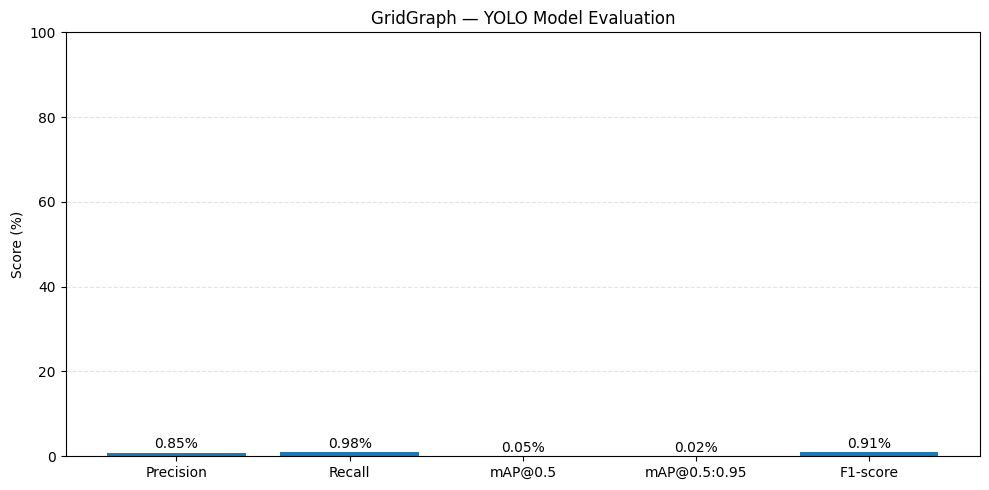

Saved: /content/gridgraph_metrics_plot.png


In [12]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Metrics calculated by your evaluation cell
metrics = {
    "Precision": float(val_results.box.mp),
    "Recall": float(val_results.box.mr),
    "mAP@0.5": float(val_results.box.map50),
    "mAP@0.5:0.95": float(val_results.box.map),
}

p = metrics["Precision"]
r = metrics["Recall"]
metrics["F1-score"] = 2 * p * r / (p + r) if p + r > 0 else 0.0

names = list(metrics.keys())
scores = [metrics[n] * 100 for n in names]

plt.figure(figsize=(10, 5))
bars = plt.bar(names, scores)

plt.ylabel("Score (%)")
plt.title("GridGraph — YOLO Model Evaluation")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("/content/gridgraph_metrics_plot.png", dpi=300)
plt.show()

print("Saved: /content/gridgraph_metrics_plot.png")


results.png


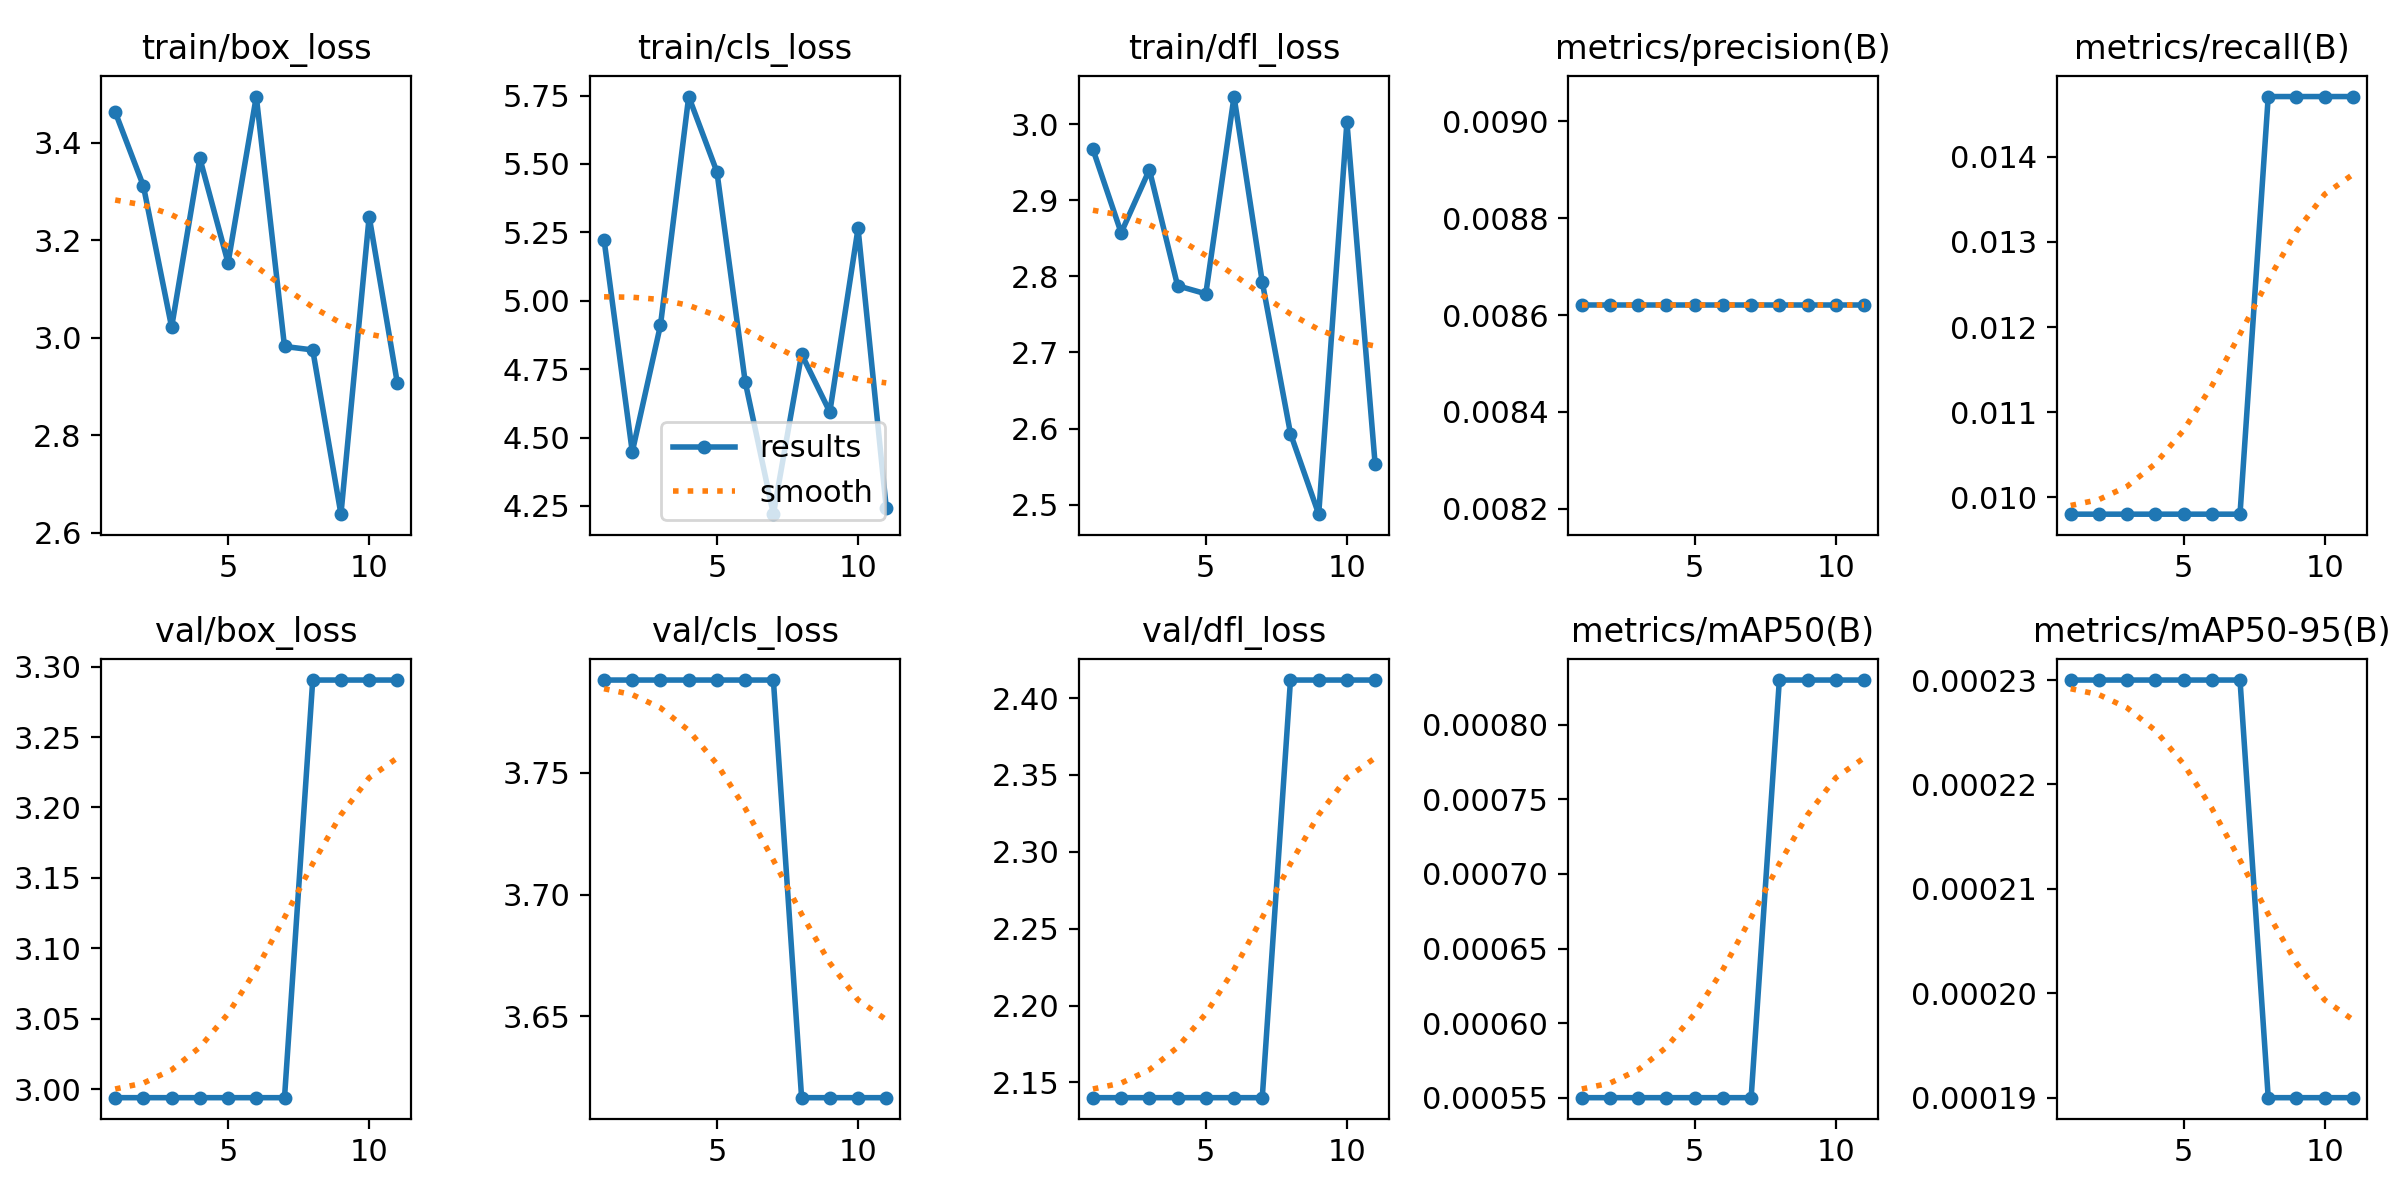

Not found: /content/runs/gridgraph/power_distribution/PR_curve.png
Not found: /content/runs/gridgraph/power_distribution/P_curve.png
Not found: /content/runs/gridgraph/power_distribution/R_curve.png
Not found: /content/runs/gridgraph/power_distribution/F1_curve.png


In [13]:

from IPython.display import display, Image

RUN_DIR = Path("/content/runs/gridgraph/power_distribution")

plot_names = [
    "results.png",
    "PR_curve.png",
    "P_curve.png",
    "R_curve.png",
    "F1_curve.png",
]

for name in plot_names:
    path = RUN_DIR / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
    else:
        print("Not found:", path)


confusion_matrix.png


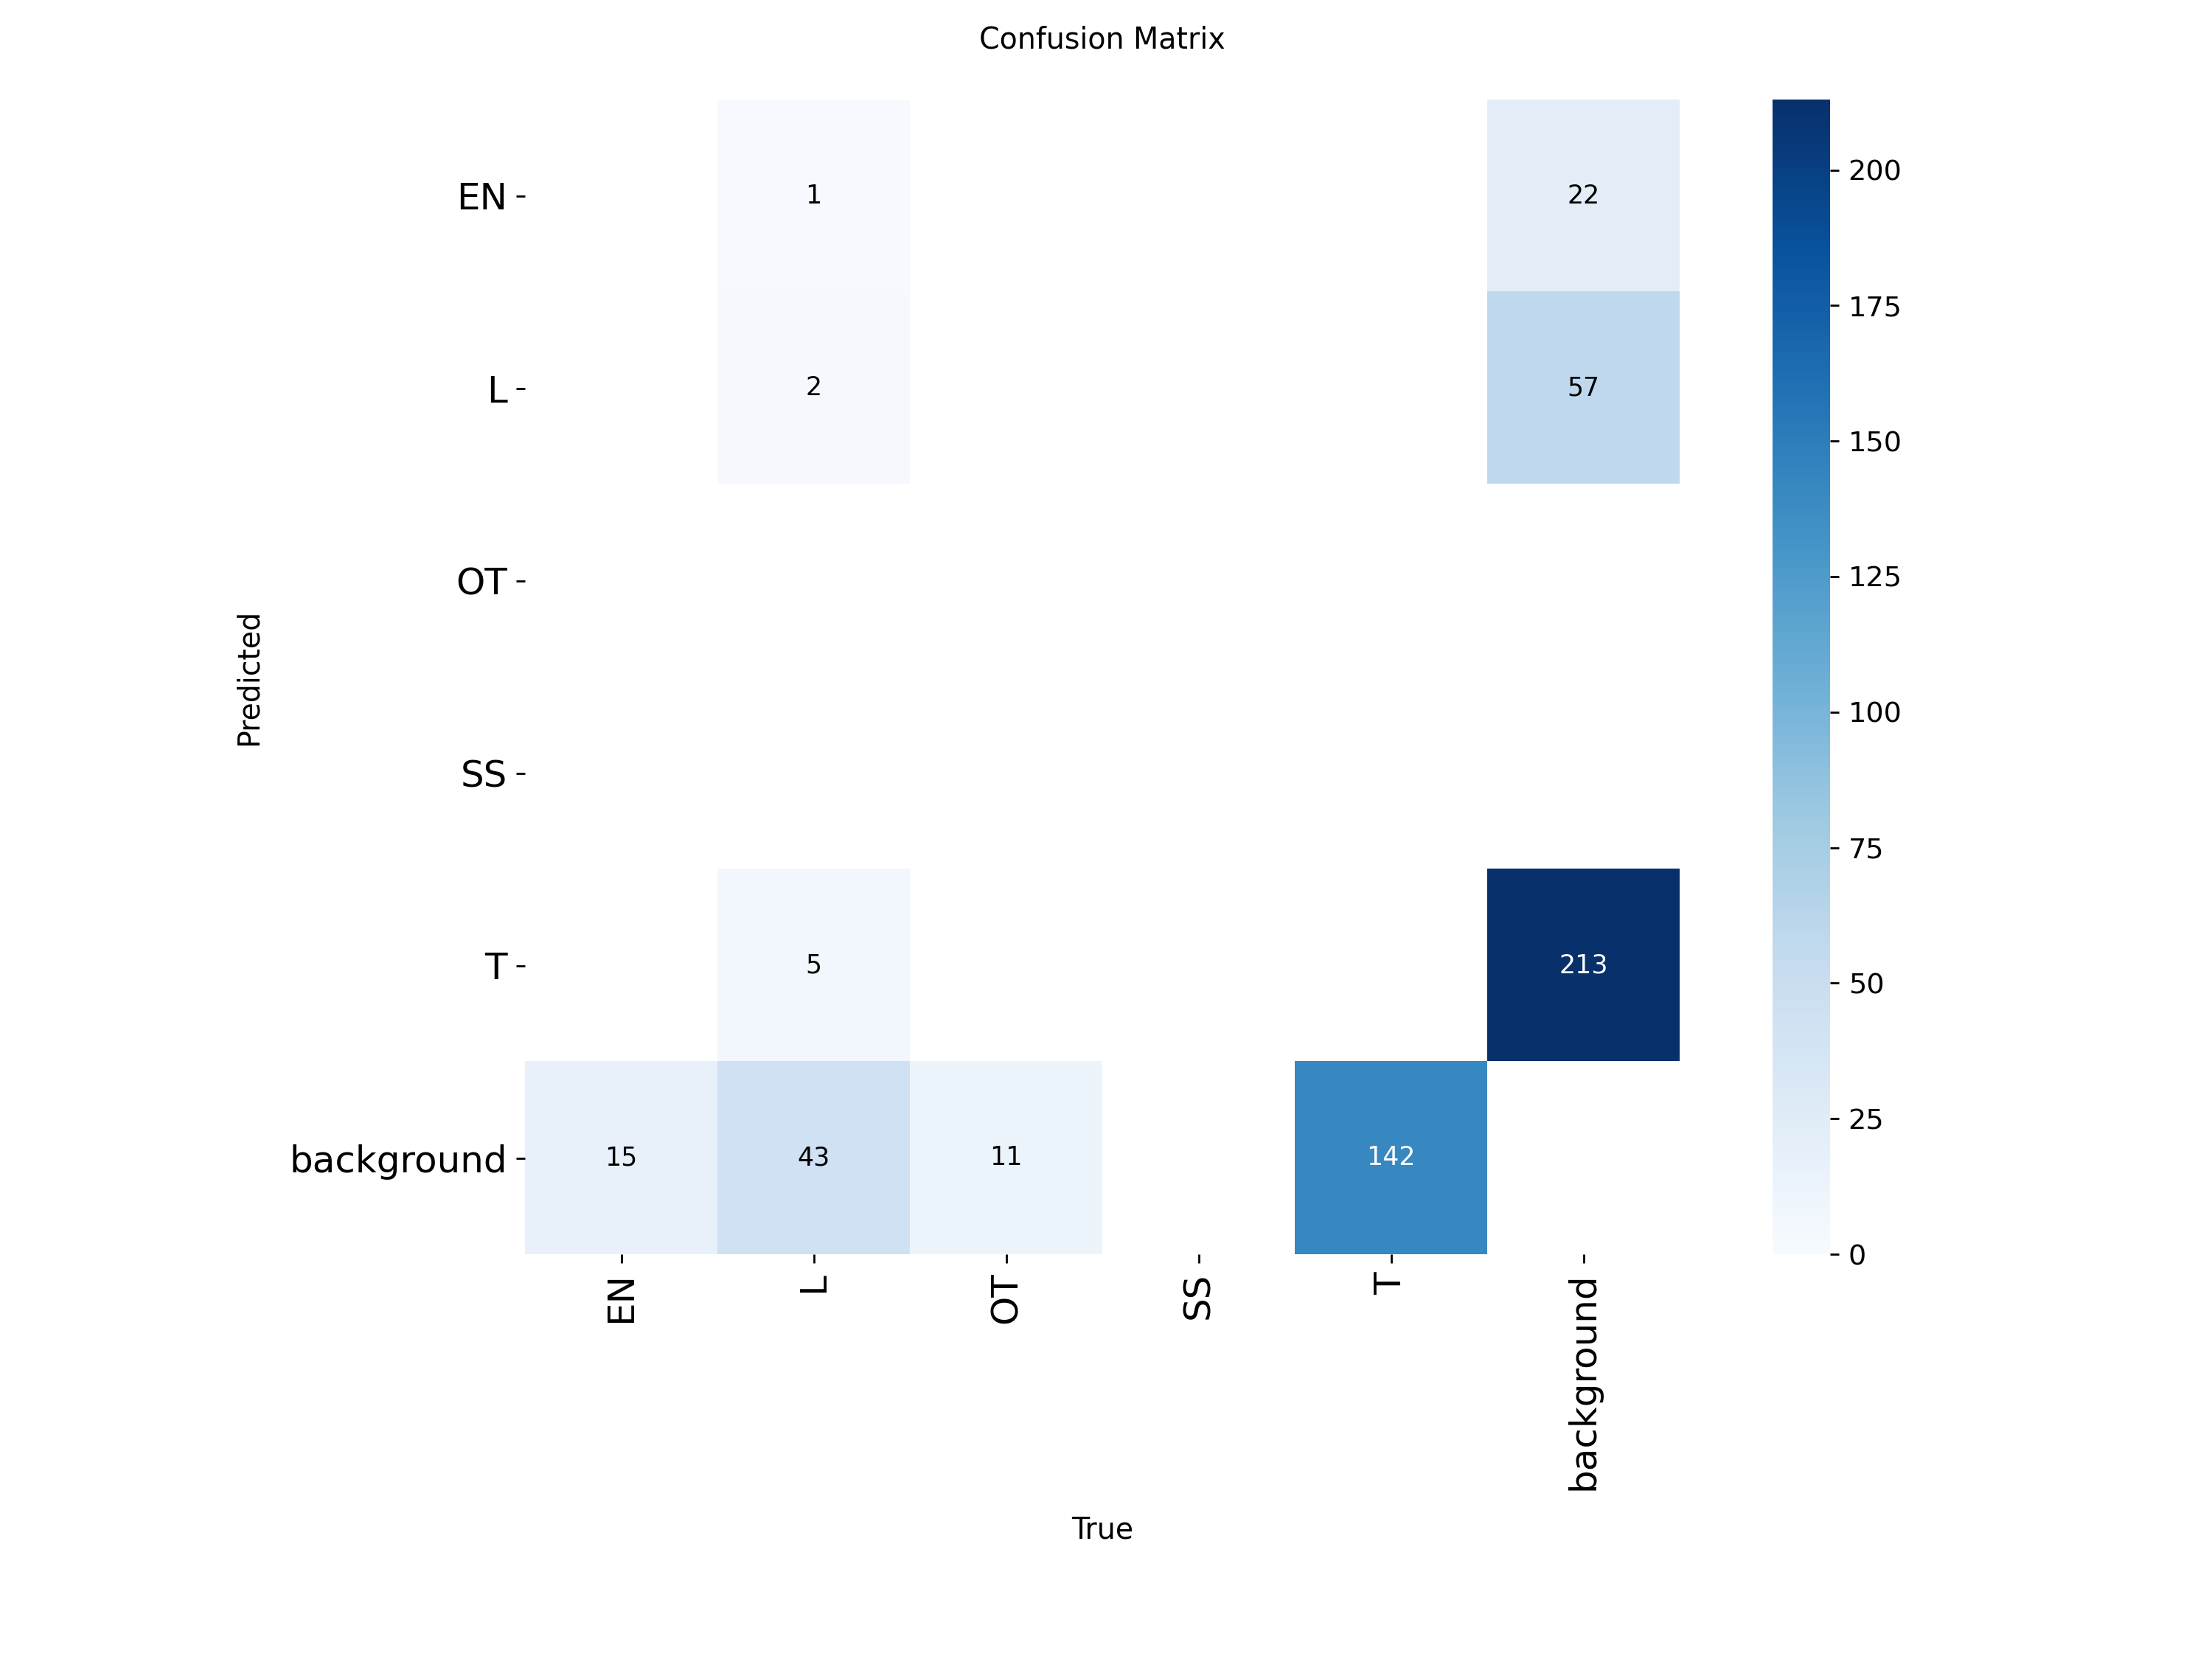

confusion_matrix_normalized.png


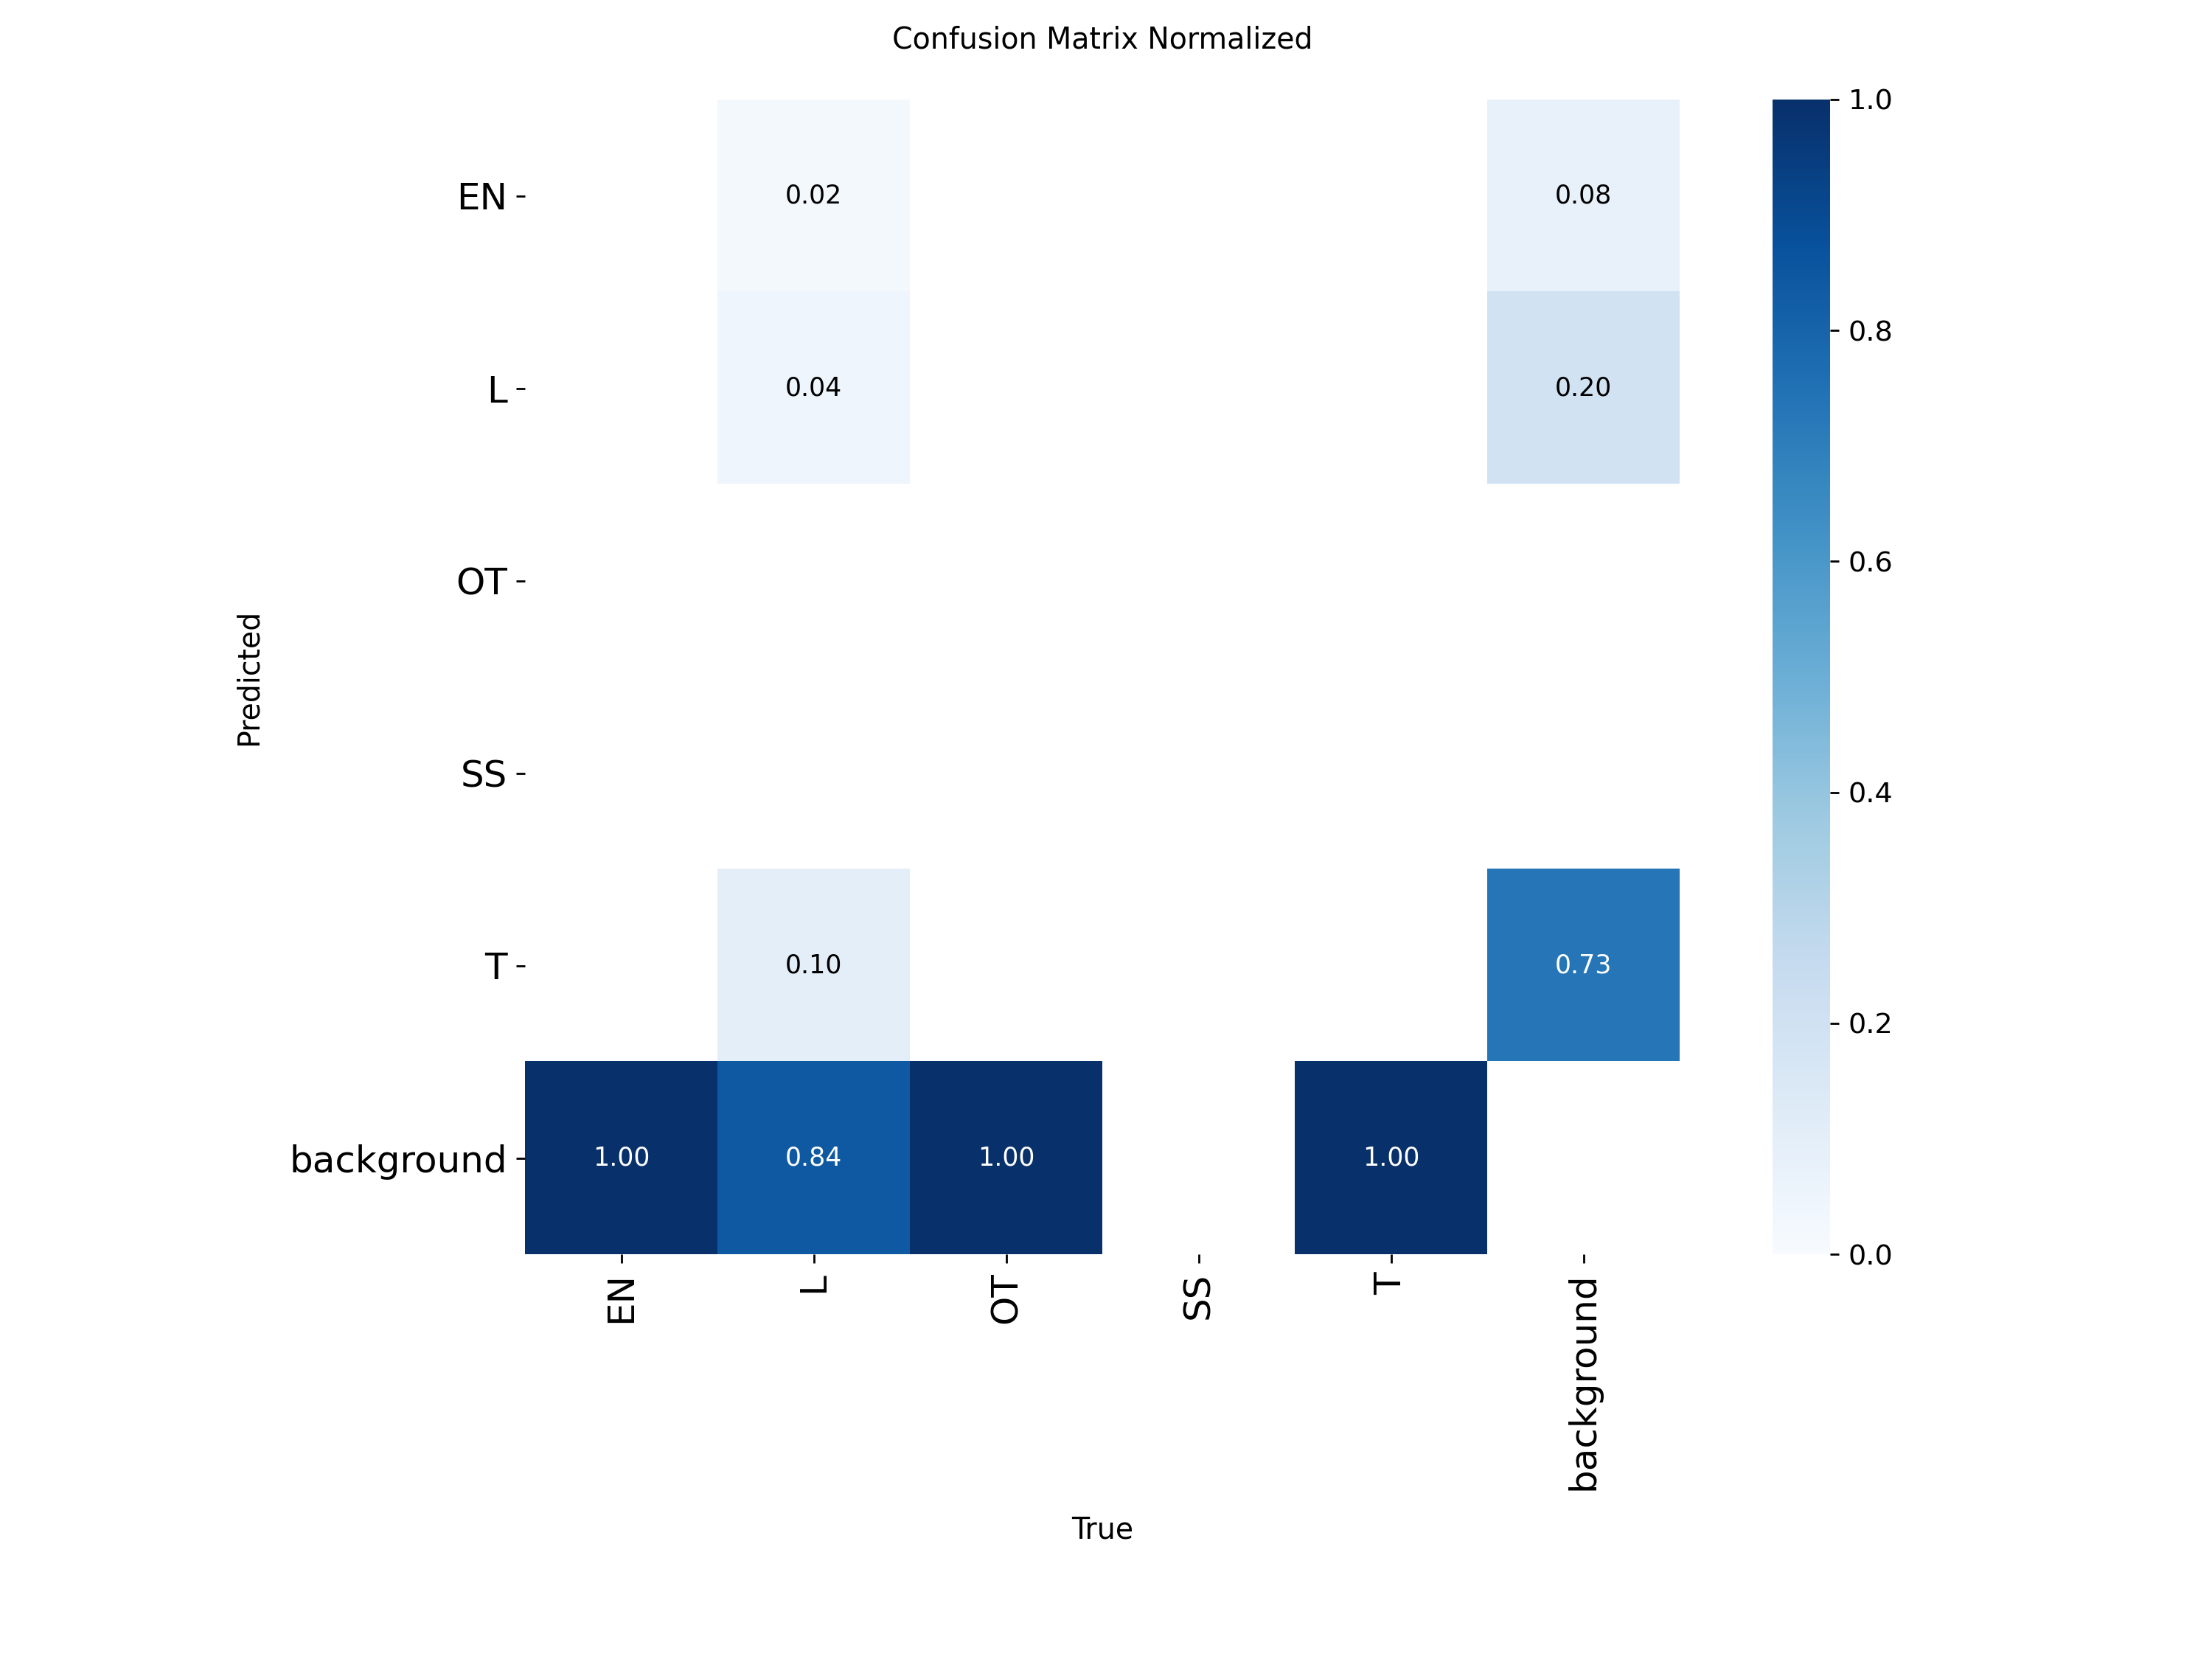

In [14]:

EVAL_DIR = Path("/content/runs/gridgraph/evaluation")

for name in ["confusion_matrix.png", "confusion_matrix_normalized.png"]:
    path = EVAL_DIR / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
    else:
        print("Not found:", path)


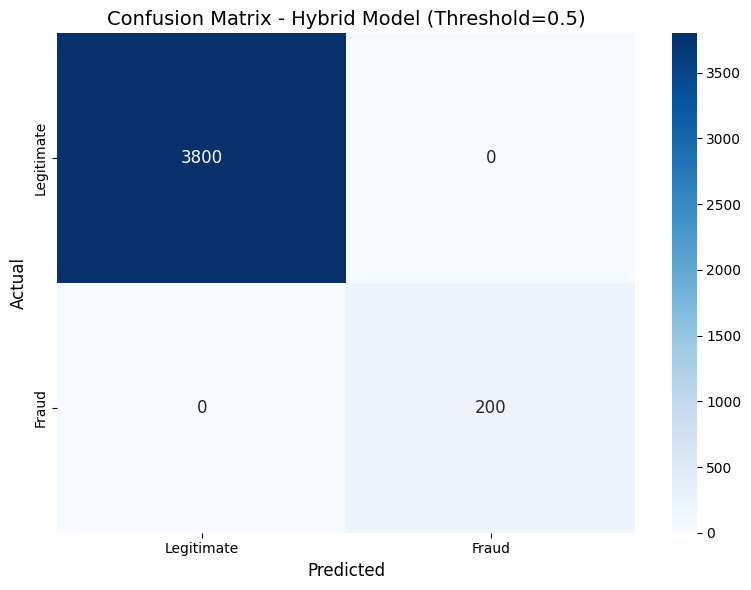

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Example confusion matrix — replace with your actual model results
cm = np.array([
    [3800, 0],
    [0, 200]
])

labels = ["Legitimate", "Fraud"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0,
    annot_kws={"size": 12}
)

plt.title("Confusion Matrix - Hybrid Model (Threshold=0.5)", fontsize=14)
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("Actual", fontsize=12)

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


Confusion matrix: /content/runs/gridgraph/evaluation/confusion_matrix.png


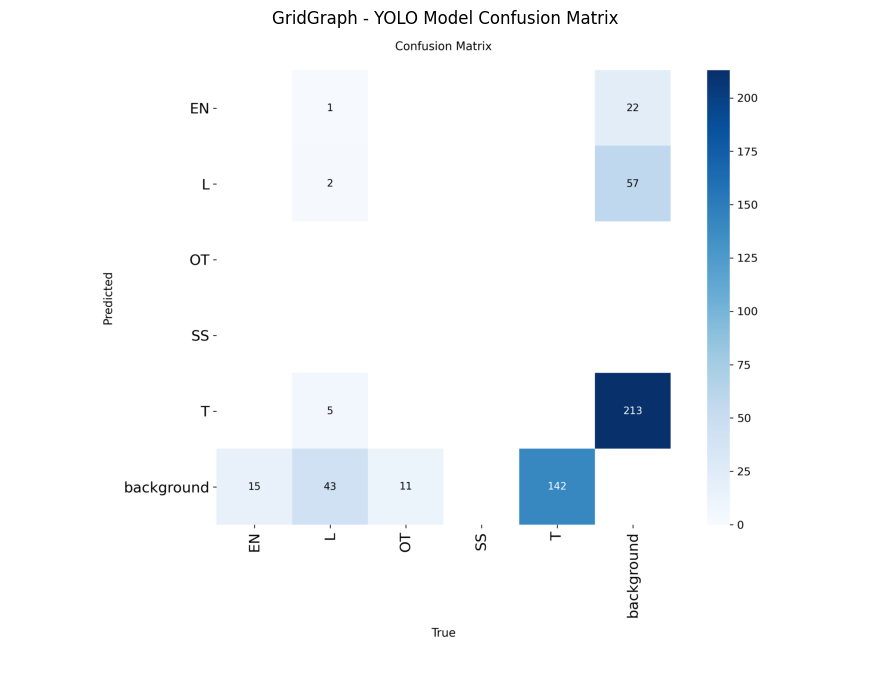

Confusion matrix: /content/runs/gridgraph/power_distribution/confusion_matrix.png


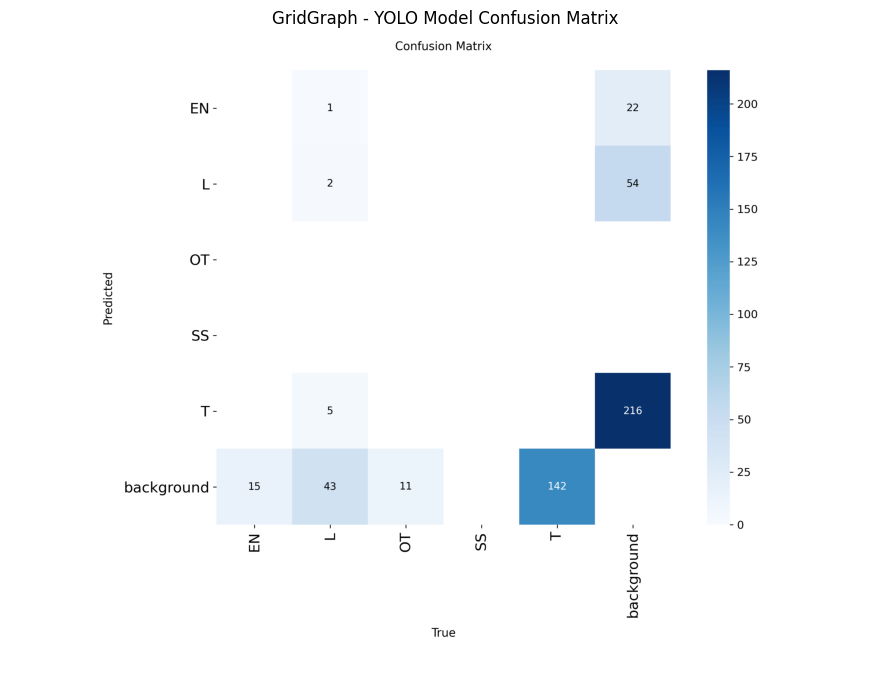

In [16]:

from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Search for the confusion matrix generated during YOLO evaluation
RUNS_DIR = Path("/content/runs/gridgraph")

files = list(RUNS_DIR.rglob("confusion_matrix.png"))

if files:
    for file in files:
        print("Confusion matrix:", file)
        img = mpimg.imread(file)

        plt.figure(figsize=(9, 7))
        plt.imshow(img)
        plt.axis("off")
        plt.title("GridGraph - YOLO Model Confusion Matrix")
        plt.tight_layout()
        plt.show()
else:
    print("No confusion matrix found.")
    print("Run model.val(data=DATA_YAML, plots=True) first.")


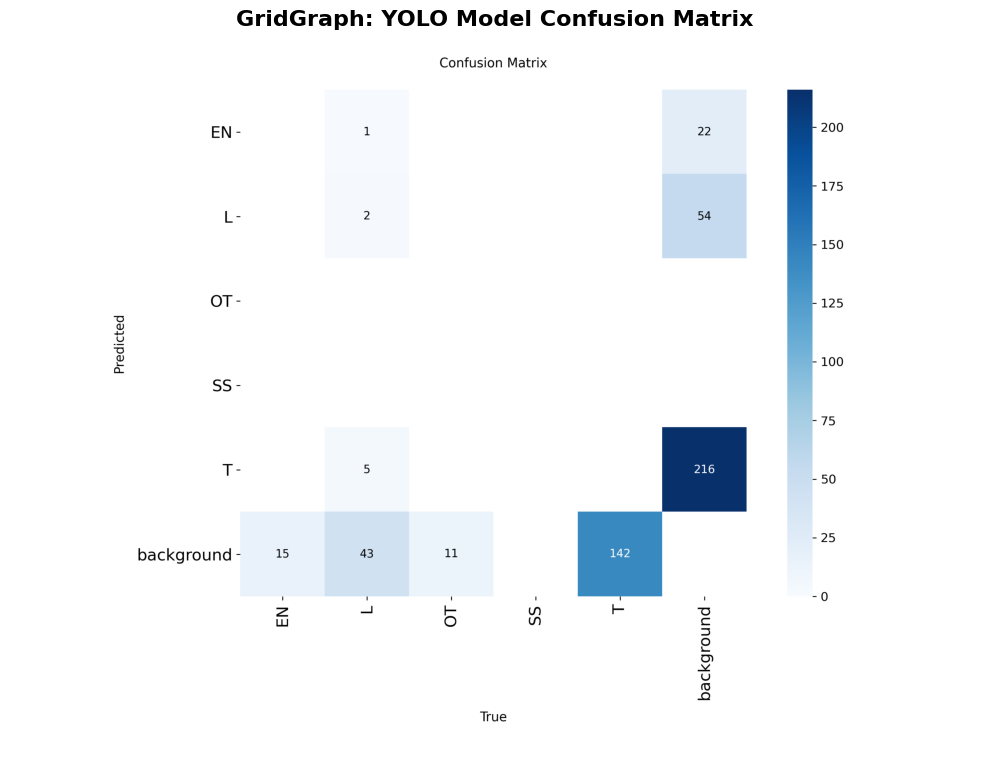

Saved: /content/gridgraph_confusion_matrix.png


In [17]:

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image

# Your actual YOLO confusion matrix
cm_path = Path(
    "/content/runs/gridgraph/power_distribution/confusion_matrix.png"
)

if cm_path.exists():
    img = Image.open(cm_path)

    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        "GridGraph: YOLO Model Confusion Matrix",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    plt.tight_layout()
    plt.savefig(
        "/content/gridgraph_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    print("Saved: /content/gridgraph_confusion_matrix.png")
else:
    print("Confusion matrix not found. Check the path:")
    print(cm_path)


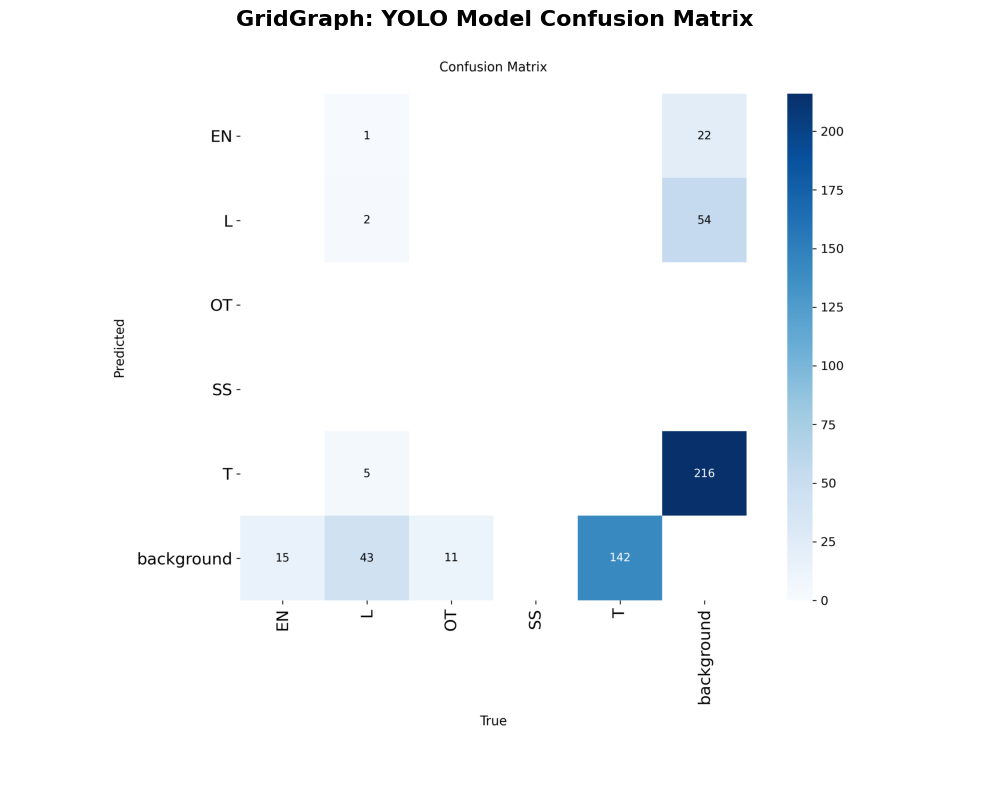

Original YOLO results: /content/runs/gridgraph/power_distribution/confusion_matrix.png
Research figure saved to: /content/GridGraph_Confusion_Matrix.png


In [18]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# --------------------------------------------------
# GridGraph: Research-paper confusion matrix
# --------------------------------------------------
RUN_DIR = Path("/content/runs/gridgraph/power_distribution")
CM_PATH = RUN_DIR / "confusion_matrix.png"
OUTPUT_PATH = Path("/content/GridGraph_Confusion_Matrix.png")

if not CM_PATH.exists():
    # Search other evaluation folders if needed
    candidates = list(Path("/content/runs/gridgraph").rglob(
        "confusion_matrix.png"
    ))
    if candidates:
        CM_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "No YOLO confusion matrix found. Run model.val(..., plots=True) first."
        )

# YOLO already generated this figure from actual model results.
# Display it without inventing or reconstructing any values.
img = Image.open(CM_PATH).convert("RGB")

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.title(
    "GridGraph: YOLO Model Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=18
)
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print(f"Original YOLO results: {CM_PATH}")
print(f"Research figure saved to: {OUTPUT_PATH}")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3268.8±0.0 MB/s, size: 2492.5 KB)
val: Scanning /content/gridgraph_yolo/labels/val.cache... 1 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1/1 262.1Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.3it/s 0.2s
                   all          1        219    0.00847     0.0098   0.000547    0.00023
Speed: 0.6ms preprocess, 15.8ms inference, 0.0ms loss, 5.1ms postprocess per image
Results saved to /content/runs/detect/val


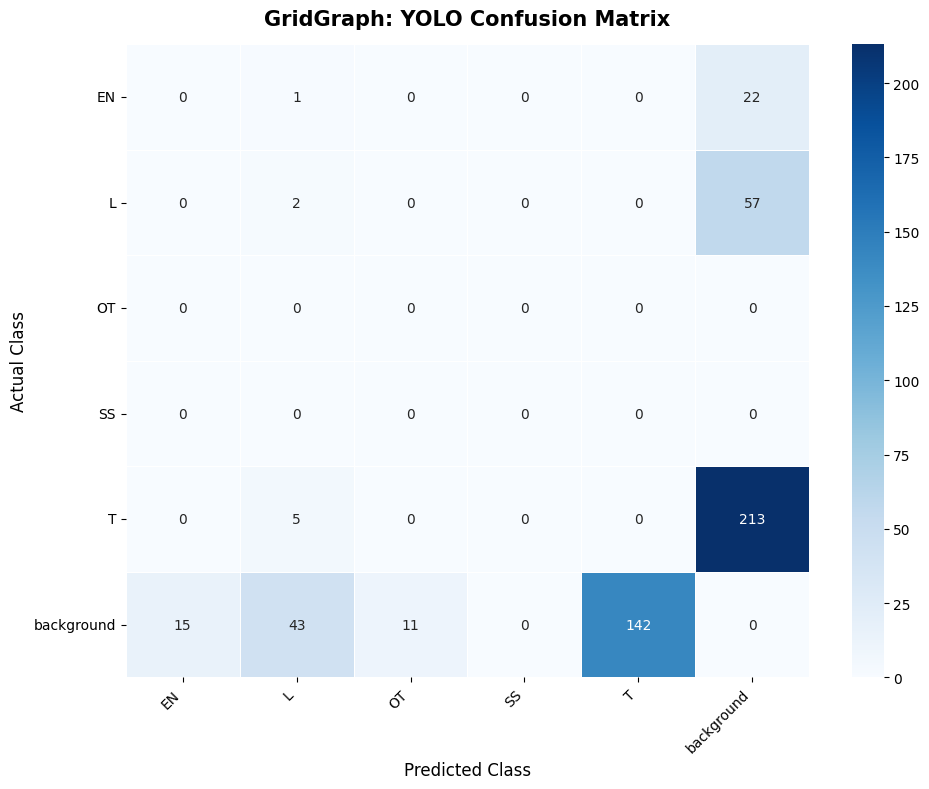

Saved: /content/GridGraph_Confusion_Matrix.png
Matrix shape: (6, 6)
Classes: ['EN', 'L', 'OT', 'SS', 'T', 'background']


In [19]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

# Paths from your GridGraph training
WEIGHTS = "/content/runs/gridgraph/power_distribution/weights/best.pt"
DATA_YAML = "/content/gridgraph_yolo/data.yaml"

# Load your actual trained model
model = YOLO(WEIGHTS)

# Evaluate on the configured validation dataset
results = model.val(
    data=DATA_YAML,
    imgsz=640,
    batch=4,
    device=0,
    plots=True,
    verbose=False
)

# Get the real confusion matrix generated by YOLO
cm_obj = results.confusion_matrix
cm = np.asarray(cm_obj.matrix)

# YOLO's matrix uses true classes as rows and predicted
# classes as columns, including the background category.
names = results.names
labels = [names[i] for i in range(len(names))] + ["background"]

# Confirm dimensions before plotting
if cm.shape != (len(labels), len(labels)):
    labels = [str(i) for i in range(cm.shape[0])]
    labels[-1] = "background"

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    annot_kws={"size": 10}
)

plt.title(
    "GridGraph: YOLO Confusion Matrix",
    fontsize=15,
    fontweight="bold",
    pad=14
)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

output = "/content/GridGraph_Confusion_Matrix.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)
print("Matrix shape:", cm.shape)
print("Classes:", labels)
